# Rural Wildfires in Portugal (SGIF 2001-2025)

## Objective

**Research question:** Do rural wildfire characteristics differ across different municipalities and between the periods before and after 2017?

1. Does the proportion of negligent versus intentional wildfires differ between the periods before and after 2017 in mainland Portugal?
2. Does the proportion of wildfires lasting 24 hours or more differ across the municipalities of Paredes, Castelo de Paiva, Évora, and Santarém?
3. Does the time to first intervention differ between the periods before and after 2017 in mainland Portugal?
4. Does the duration of rural wildfires differ across the municipalities of Paredes, Castelo de Paiva, Évora, and Santarém?
5. Is the time to first intervention associated with the burned area of rural wildfires in mainland Portugal?

## Variables per question

| Question | Response variable | Explanatory variable |
|---|---|---|
| 1 | `TipoCausa` (negligent / intentional) | period, from `Ano` |
| 2 | `IncSup24horas` (more than 24 h or not) | `Concelho` |
| 3 | time to first intervention = `DataHora_PrimeiraIntervencao` - `DataHoraAlerta` | period, from `Ano` |
| 4 | `Duracao_Horas` | `Concelho` |
| 5 | `AreaTotal_ha` | time to first intervention |

What each one is:

- `Codigo_SGIF`: id of the fire in the SGIF system
- `Ano`: year of the fire
- `Distrito`, `Concelho`: district and municipality
- `TipoCausa`: type of cause (Negligente, Intencional, Natural, Reacendimento, Desconhecida)
- `DataHoraAlerta`: date and time of the alert
- `DataHora_PrimeiraIntervencao`: date and time the first team started fighting the fire
- `DataHora_Extincao`: date and time the fire was put out
- `Duracao_Horas`: hours from alert to extinction
- `IncSup24horas`: 1 if the fire lasted more than 24 hours, 0 otherwise
- `AreaTotal_ha`: total burned area in hectares

`Distrito` and `DataHora_Extincao` are not in any question, we keep them to check `Concelho` and `Duracao_Horas`.

## Parameters

In [2]:
LAST_YEAR_BEFORE = 2017      # 2017 counts as "before". change to 2016 to move it to "after"
MUNICIPALITIES = ["Paredes", "Castelo de Paiva", "Évora", "Santarém"]

## Import data

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

data2001_2010 = pd.read_excel("Registos_Incendios_SGIF_2001_2010.xlsx")
data2011_2020 = pd.read_excel("Registos_Incendios_SGIF_2011_2020.xlsx")
data2021_2025 = pd.read_excel("Registos_Incendios_SGIF_2021_2025.xlsx")

# the three files have the same columns, so we stack them
data = pd.concat([data2001_2010, data2011_2020, data2021_2025], ignore_index=True)
data.shape

(497478, 41)

## Keep only the variables we need

In [6]:
keep = ["Codigo_SGIF", "Ano", "Distrito", "Concelho", "TipoCausa",
        "DataHoraAlerta", "DataHora_PrimeiraIntervencao", "DataHora_Extincao",
        "Duracao_Horas", "IncSup24horas", "AreaTotal_ha"]
unused = [c for c in data.columns if c not in keep]

print("before:", data.shape)
print("dropped:", unused)
data = data.drop(columns=unused)
print("after: ", data.shape)
data.head()

before: (497478, 41)
dropped: ['Codigo_ANEPC', 'Mes', 'Dia', 'Hora', 'AreaPov_ha', 'AreaMato_ha', 'AreaAgric_ha', 'ClasseArea', 'DTCCFR', 'Freguesia', 'Local', 'RNAP', 'RNMPF', 'X_Militar', 'Y_Militar', 'Latitude', 'Longitude', 'X_ETRS89', 'Y_ETRS89', 'DSR', 'FWI', 'ISI', 'DC', 'DMC', 'FFMC', 'BUI', 'CodCausa', 'GrupoCausa', 'DescricaoCausa', 'FonteAlerta']
after:  (497478, 11)


,Codigo_SGIF,Ano,AreaTotal_ha,DataHoraAlerta,DataHora_PrimeiraIntervencao,DataHora_Extincao,Duracao_Horas,IncSup24horas,Distrito,Concelho,TipoCausa
0,AT901106,2001,0.0001,2001-01-05 02:00:00,NaT,2001-01-05 02:51:00,0.850000,0,Beja,Cuba,NaN
1,BL201479,2001,0.0100,2001-01-05 14:18:00,NaT,2001-01-05 14:23:00,0.083333,0,Coimbra,Coimbra,NaN
2,TM90152,2001,0.0100,2001-01-05 21:00:00,NaT,2001-01-05 22:35:00,1.583333,0,Bragança,Mirandela,NaN
3,BL101313,2001,0.1000,2001-01-06 13:05:00,NaT,2001-01-06 13:15:00,0.166667,0,Aveiro,Albergaria-a-Velha,NaN
4,BL201156,2001,0.0000,2001-01-07 00:16:00,NaT,2001-01-07 01:20:00,1.066667,0,Coimbra,Coimbra,NaN


## Data check

In [7]:
data.dtypes

Codigo_SGIF                             object
Ano                                      int64
AreaTotal_ha                           float64
DataHoraAlerta                  datetime64[ns]
DataHora_PrimeiraIntervencao    datetime64[ns]
DataHora_Extincao                       object
Duracao_Horas                          float64
IncSup24horas                            int64
Distrito                                object
Concelho                                object
TipoCausa                               object
dtype: object

In [8]:
# missing values per column
data.isna().sum()

Codigo_SGIF                          0
Ano                                  0
AreaTotal_ha                         0
DataHoraAlerta                       0
DataHora_PrimeiraIntervencao    214771
DataHora_Extincao                  513
Duracao_Horas                      513
IncSup24horas                        0
Distrito                             1
Concelho                             1
TipoCausa                       249994
dtype: int64

In [9]:
# missing values per year, only columns that have some
cols_na = data.columns[data.isna().any()]
data[cols_na].isna().groupby(data["Ano"]).sum()

,DataHora_PrimeiraIntervencao,DataHora_Extincao,Duracao_Horas,Distrito,Concelho,TipoCausa
Ano,,,,,,
2001,28915,0,0,0,0,26644
2002,28993,0,0,0,0,26327
2003,28087,0,0,0,0,25724
2004,27829,0,0,0,0,25691
2005,41689,0,0,0,0,38237
2006,24192,0,0,0,0,21169
2007,25131,0,0,0,0,15585
2008,2917,0,0,0,0,9185
2009,4045,1,1,0,0,15084


In [10]:
print("rows:", len(data))
print("unique Codigo_SGIF:", data["Codigo_SGIF"].nunique())
print("years:", data["Ano"].min(), "to", data["Ano"].max())

# Codigo_SGIF comes as text in some files and as number in others
data["Codigo_SGIF"].map(type).value_counts()

rows: 497478
unique Codigo_SGIF: 497478
years: 2001 to 2025


Codigo_SGIF
<class 'str'>    475448
<class 'int'>     22030
Name: count, dtype: int64

In [11]:
data[["Duracao_Horas", "IncSup24horas", "AreaTotal_ha"]].describe()

,Duracao_Horas,IncSup24horas,AreaTotal_ha
count,496965.000000,497478.000000,497478.000000
mean,1.947655,0.007210,6.994419
std,7.995199,0.084607,235.970910
min,0.000000,0.000000,0.000000
25%,0.566667,0.000000,0.010000
50%,1.033333,0.000000,0.050000
75%,1.800000,0.000000,0.500000
max,2474.316667,1.000000,65478.286936


In [12]:
print(data["TipoCausa"].value_counts(dropna=False))
print()
print(data["Distrito"].value_counts())

TipoCausa
NaN              249994
Desconhecida      84395
Negligente        83660
Intencional       48013
Reacendimento     29376
Natural            2040
Name: count, dtype: int64

Distrito
Porto               105679
Braga                57121
Aveiro               40812
Lisboa               40704
Viseu                39210
Vila Real            32471
Viana do Castelo     29424
Santarém             22334
Setúbal              19149
Guarda               17764
Leiria               17492
Bragança             16176
Coimbra              15063
Castelo Branco       12887
Faro                  9385
Beja                  7195
Portalegre            6310
Évora                 6236
Viana Do Castelo      2064
BRAGA                    1
Name: count, dtype: int64


In [13]:
# our municipalities, ignoring upper/lower case
ours = [m.lower() for m in MUNICIPALITIES]
mask = data["Concelho"].str.lower().isin(ours)
data.loc[mask].groupby(["Distrito", "Concelho"]).size()

Distrito  Concelho        
Aveiro    Castelo De Paiva       41
          Castelo de Paiva     1359
Porto     Paredes             12512
Santarém  Santarém             2987
Évora     Évora                1632
dtype: int64

What we see:

- No duplicated fires: one row per `Codigo_SGIF`. But the id comes as text in some files and as a number in others, so it has to be one type.
- All 18 districts are in mainland Portugal, so there is nothing to remove for "mainland". `Distrito` has case problems (`Viana Do Castelo`, `BRAGA`).
- `Castelo de Paiva` also shows up as `Castelo De Paiva` (41 fires). The four municipalities fall in the expected districts.
- `TipoCausa` is missing for 250k fires, mostly before 2014. This matters for question 1.
- `DataHora_PrimeiraIntervencao` is missing in almost all fires from 2001 to 2007, so question 3 and 5 have little data there.
- `Duracao_Horas` and `DataHora_Extincao` are missing in the same 513 rows. Duration goes from 0 to 2474 hours.
- One fire in 2024 has no `Distrito` or `Concelho`.

## Municipality: look first

Questions 2 and 4 compare four municipalities, so `Concelho` has to be clean. Before changing anything we check how the names look.

In [14]:
# same municipality written with different upper/lower case?
names = pd.Series(data["Concelho"].dropna().unique())
groups = names.groupby(names.str.lower()).apply(list)

print("different names:        ", len(names))
print("names ignoring the case:", len(groups))
groups[groups.map(len) > 1].head(8)

different names:         379
names ignoring the case: 278


aguiar da beira             [Aguiar da Beira, Aguiar Da Beira]
albergaria-a-velha    [Albergaria-a-Velha, Albergaria-a-velha]
alcácer do sal                [Alcácer do Sal, Alcácer Do Sal]
alfândega da fé             [Alfândega Da Fé, Alfândega da Fé]
alijó                                           [Alijó, ALIJÓ]
alter do chão                   [Alter do Chão, Alter Do Chão]
arcos de valdevez       [Arcos de Valdevez, Arcos De Valdevez]
arruda dos vinhos       [Arruda dos Vinhos, Arruda Dos Vinhos]
dtype: object

In [15]:
# how many municipalities are written in more than one way, and how many fires they have
spellings = data.groupby(data["Concelho"].str.lower())["Concelho"].nunique()
mixed = spellings[spellings > 1].index

print("municipalities written in more than one way:", len(mixed))
print("fires in those municipalities:              ", data["Concelho"].str.lower().isin(mixed).sum())

municipalities written in more than one way: 94
fires in those municipalities:               184688


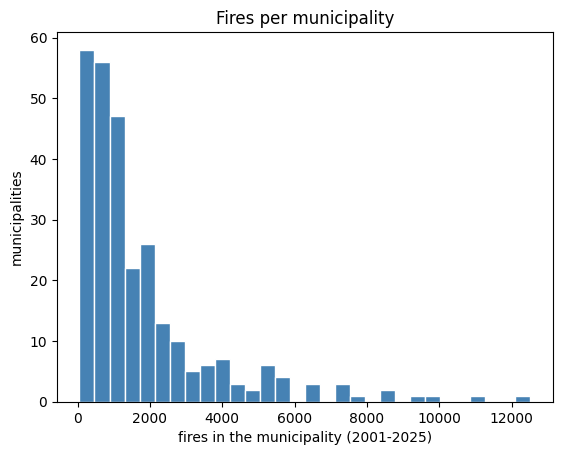

count      278.000000
mean      1789.485612
std       1984.978883
min         53.000000
25%        542.250000
50%       1100.000000
75%       2112.750000
max      12512.000000
Name: count, dtype: float64

In [16]:
# fires per municipality once the case is the same
per_concelho = data["Concelho"].str.lower().value_counts()

fig, ax = plt.subplots()
ax.hist(per_concelho, bins=30, color="steelblue", edgecolor="white")
ax.set_xlabel("fires in the municipality (2001-2025)")
ax.set_ylabel("municipalities")
ax.set_title("Fires per municipality")
plt.show()

per_concelho.describe()

In [17]:
# the fire with no municipality
data[data["Concelho"].isna()]

,Codigo_SGIF,Ano,AreaTotal_ha,DataHoraAlerta,DataHora_PrimeiraIntervencao,DataHora_Extincao,Duracao_Horas,IncSup24horas,Distrito,Concelho,TipoCausa
488791,20241176561,2024,0.0001,2024-09-21 08:08:00,2024-09-21 08:20:00,2024-09-21 08:50:00,0.7,0,NaN,NaN,NaN


What we see:

- The names only differ in upper/lower case (`Castelo de Paiva` / `Castelo De Paiva`, `Alijó` / `ALIJÓ`). Ignoring the case we go from 379 to 278 names, the number of municipalities in mainland Portugal, so no two different municipalities are mixed.
- Of our four municipalities only Castelo de Paiva is affected: 41 of its 1400 fires. Without fixing it we would lose them when we filter.
- Fires per municipality are very skewed: median 1100, from 53 (Barrancos) to 12512 (Paredes). The groups of questions 2 and 4 will be unbalanced.
- Only one fire has no municipality. It looks like a good record, but it is 1 fire out of 497478 and it can't be one of our four municipalities, so we remove it.

## Cleaning: municipality and types

We work at the municipality level (`Concelho`). Paredes and Castelo de Paiva are only municipalities. Évora and Santarém are also district names, but we want the municipality, not the whole district (for example Évora has 6236 fires as a district and 1632 as a municipality).

`Distrito` was only kept to check that, so we drop it now.

In [18]:
# the fire with no municipality can't be used
print("no Concelho:", data["Concelho"].isna().sum())
data = data.dropna(subset=["Concelho"])

data = data.drop(columns=["Distrito"])
data.shape

no Concelho: 1


(497477, 10)

In [19]:
# same case for every municipality: "Castelo de Paiva" / "Castelo De Paiva", "ODIVELAS" / "Odivelas"
print("names before:", data["Concelho"].nunique())
data["Concelho"] = data["Concelho"].str.lower()
print("names after: ", data["Concelho"].nunique())

MUNICIPALITIES = [m.lower() for m in MUNICIPALITIES]
data.loc[data["Concelho"].isin(MUNICIPALITIES), "Concelho"].value_counts()

names before: 379
names after:  278


Concelho
paredes             12512
santarém             2987
évora                1632
castelo de paiva     1400
Name: count, dtype: int64

From 379 names to 278. Castelo de Paiva goes from 1359 to 1400 fires. Everything is in lower case, also the labels of the plots.

In [20]:
# the id is an id, not a number
data["Codigo_SGIF"] = data["Codigo_SGIF"].astype("string")

# text with few values -> category
data["Concelho"] = data["Concelho"].astype("category")
data["TipoCausa"] = data["TipoCausa"].astype("category")

data.dtypes

Codigo_SGIF                     string[python]
Ano                                      int64
AreaTotal_ha                           float64
DataHoraAlerta                  datetime64[ns]
DataHora_PrimeiraIntervencao    datetime64[ns]
DataHora_Extincao                       object
Duracao_Horas                          float64
IncSup24horas                            int64
Concelho                              category
TipoCausa                             category
dtype: object

## Period

We compare fires up to 2017 ("before") with fires from 2018 on ("after"), following the theme proposed for the project: the human influence in fire ignitions before and after 2017 and in different regions.

The cut is the same in every question, but the first year of "before" depends on the data each question needs:

- Question 1 will use all the years (before = 2001-2017), with the limitations of the cause which will be shown below.
- Questions 3 and 5 will start in 2008 (before = 2008-2017), because there is almost no first intervention date before 2008.

In [21]:
# before = up to LAST_YEAR_BEFORE, after = the rest
data["period"] = "after"
data.loc[data["Ano"] <= LAST_YEAR_BEFORE, "period"] = "before"
data["period"] = data["period"].astype("category")

data.groupby("period")["Ano"].agg(["min", "max", "count"])

C:\Users\Maria Mota\AppData\Local\Temp\ipykernel_22812\1963441539.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby("period")["Ano"].agg(["min", "max", "count"])


,min,max,count
period,,,
after,2018,2025,73330
before,2001,2017,424147


## Question 1: cause

### Cause: look first

Question 1 compares negligent and intentional fires, so we check how `TipoCausa` is filled in each year before deciding anything.

In [22]:
# cause of the fires per year, the missing ones included
cause = data["TipoCausa"].astype(str)          # missing shows up as "nan"
by_year = pd.crosstab(data["Ano"], cause)
by_year = by_year[["Negligente", "Intencional", "Desconhecida", "Reacendimento", "Natural", "nan"]]
by_year["% missing"] = (by_year["nan"] / by_year.sum(axis=1) * 100).round(0)
by_year

TipoCausa,Negligente,Intencional,Desconhecida,Reacendimento,Natural,nan,% missing
Ano,,,,,,,
2001,391,475,208,1159,38,26644,92.0
2002,414,394,221,1625,12,26327,91.0
2003,522,436,230,1098,77,25724,92.0
2004,421,364,284,1055,14,25691,92.0
2005,456,619,377,1997,3,38237,92.0
2006,502,381,1804,304,83,21169,87.0
2007,3203,1424,4292,565,63,15585,62.0
2008,3490,1570,4367,319,28,9185,48.0
2009,5190,3540,4571,1272,126,15084,51.0


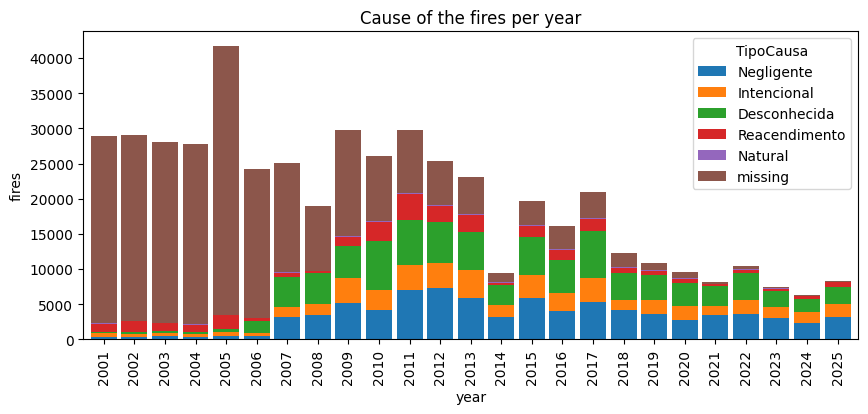

In [23]:
counts = by_year.drop(columns="% missing").rename(columns={"nan": "missing"})

ax = counts.plot(kind="bar", stacked=True, figsize=(10, 4), width=0.85)
ax.set_xlabel("year")
ax.set_ylabel("fires")
ax.set_title("Cause of the fires per year")
plt.show()

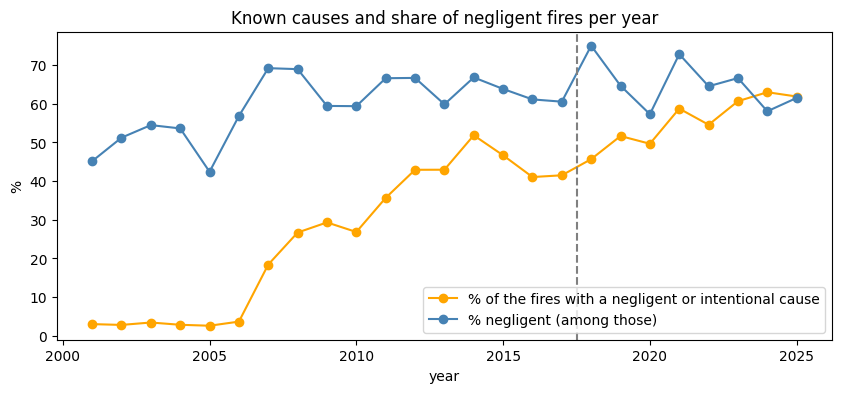

In [24]:
known = by_year["Negligente"] + by_year["Intencional"]
share_known = known / counts.sum(axis=1) * 100
share_negligent = by_year["Negligente"] / known * 100

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(share_known.index, share_known, marker="o", color="orange", label="% of the fires with a negligent or intentional cause")
ax.plot(share_negligent.index, share_negligent, marker="o", color="steelblue", label="% negligent (among those)")
ax.axvline(LAST_YEAR_BEFORE + 0.5, color="gray", ls="--")
ax.set_xlabel("year")
ax.set_ylabel("%")
ax.set_title("Known causes and share of negligent fires per year")
ax.legend()
plt.show()

In [25]:
# are the fires with a known cause different from the others?
kind = pd.Series("other cause", index=data.index)
kind[data["TipoCausa"].isin(["Negligente", "Intencional"])] = "negligent / intentional"
kind[data["TipoCausa"].isna()] = "missing cause"
when = (data["Ano"] <= LAST_YEAR_BEFORE).map({True: "before", False: "after"})

data.groupby([when, kind])["AreaTotal_ha"].agg(["count", "median", "mean"]).round(2)

count  median   mean
Ano                                                  
after  missing cause              4772    0.02   3.60
       negligent / intentional   40073    0.10  12.62
       other cause               28485    0.04   7.45
before missing cause            245221    0.05   2.28
       negligent / intentional   91600    0.15  15.54
       other cause               87326    0.04   8.72

What we see:

- Up to 2006 almost no cause is recorded (87% to 92% missing). From 2007 it improves every year, and since 2021 less than 3% is missing.
- Before 2018 only 22% of the fires have a negligent or intentional cause, after 2017 it is 55%.
- Among them the share of negligent fires is 50% in 2001-2006 and 63% to 65% from 2007 on.
- The fires with a known cause are bigger (median 0.15 ha against 0.05 ha for the missing ones before 2018), so they are not a random sample of all the fires.

We use all the years (before = 2001-2017) and we keep the points above as limitations of question 1.

In [26]:
# astype(str) so the missing causes show up as "nan"
pd.crosstab(data["TipoCausa"].astype(str), data["period"], margins=True)

period,after,before,All
TipoCausa,,,
Desconhecida,23829,60566,84395
Intencional,13872,34141,48013
Natural,836,1204,2040
Negligente,26201,57459,83660
Reacendimento,3820,25556,29376
nan,4772,245221,249993
All,73330,424147,497477


In [27]:
# only fires with a known negligent or intentional cause
q1 = data[data["TipoCausa"].isin(["Negligente", "Intencional"])]

tab = pd.crosstab(q1["period"], q1["TipoCausa"].astype(str), margins=True)
tab["share negligent"] = (tab["Negligente"] / tab["All"]).round(3)
tab

TipoCausa,Intencional,Negligente,All,share negligent
period,,,,
after,13872,26201,40073,0.654
before,34141,57459,91600,0.627
All,48013,83660,131673,0.635


In [28]:
# how many causes were classified each year
by_year = pd.crosstab(q1["Ano"], q1["TipoCausa"].astype(str))
by_year["share negligent"] = (by_year["Negligente"] / by_year.sum(axis=1)).round(2)
by_year

TipoCausa,Intencional,Negligente,share negligent
Ano,,,
2001,475,391,0.45
2002,394,414,0.51
2003,436,522,0.54
2004,364,421,0.54
2005,619,456,0.42
2006,381,502,0.57
2007,1424,3203,0.69
2008,1570,3490,0.69
2009,3540,5190,0.59


For question 1 we keep only the fires with cause `Negligente` or `Intencional`. Missing, unknown, rekindling and natural causes are left out, we don't impute a cause.

## Questions 2 and 4: duration

In [29]:
print("missing duration:", data["Duracao_Horas"].isna().sum())
print("duration = 0:    ", (data["Duracao_Horas"] == 0).sum())

missing duration: 513
duration = 0:     636


A fire can't be put out the same minute it is reported, and without duration there is nothing to analyze. But these fires are fine for the other questions (cause, intervention time, area), so we don't remove them from `data`. We only leave them out of `q24`, the dataset of questions 2 and 4.

In [30]:
# IncSup24horas should be 1 when the fire lasted 24 hours or more
print("mismatches with > 24: ", ((data["Duracao_Horas"] > 24).astype(int) != data["IncSup24horas"]).sum())
print("mismatches with >= 24:", ((data["Duracao_Horas"] >= 24).astype(int) != data["IncSup24horas"]).sum())

mismatches with > 24:  29
mismatches with >= 24: 0


The 29 mismatches are fires of exactly 24 hours. SGIF counts them as "more than 24 hours", so `IncSup24horas` is fine as it is.

In [31]:
# the four municipalities, only fires with a real duration (not missing and not 0)
q24 = data[data["Concelho"].isin(MUNICIPALITIES) & (data["Duracao_Horas"] > 0)].copy()
q24["Concelho"] = q24["Concelho"].cat.remove_unused_categories()

pd.crosstab(q24["Concelho"], q24["IncSup24horas"], margins=True)

IncSup24horas,0,1,All
Concelho,,,
castelo de paiva,1384,8,1392
paredes,12456,36,12492
santarém,2959,26,2985
évora,1622,9,1631
All,18421,79,18500


In [32]:
q24.groupby("Concelho")["Duracao_Horas"].describe()

C:\Users\Maria Mota\AppData\Local\Temp\ipykernel_22812\1401063168.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  q24.groupby("Concelho")["Duracao_Horas"].describe()


,count,mean,std,min,25%,50%,75%,max
Concelho,,,,,,,,
castelo de paiva,1392.0,1.790577,4.209986,0.050000,0.566667,1.083333,1.666667,83.250000
paredes,12492.0,1.278609,2.831771,0.016667,0.500000,0.816667,1.250000,143.600000
santarém,2985.0,1.552446,4.063688,0.016667,0.383333,0.816667,1.450000,82.666667
évora,1631.0,1.280421,2.416428,0.066667,0.416667,0.700000,1.250000,29.050000


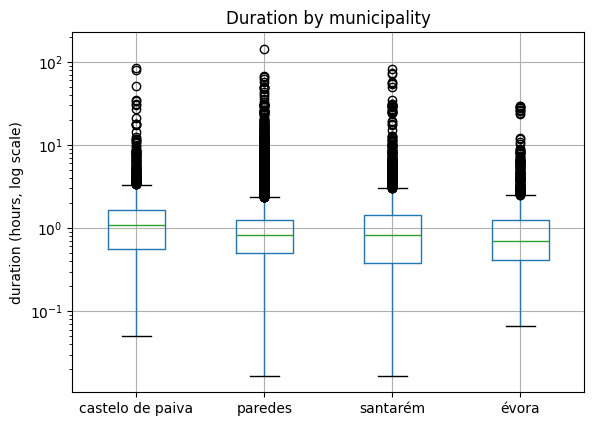

In [33]:
fig, ax = plt.subplots()
q24.boxplot(column="Duracao_Horas", by="Concelho", ax=ax)
ax.set_yscale("log")
ax.set_xlabel("")
ax.set_ylabel("duration (hours, log scale)")
ax.set_title("Duration by municipality")
plt.suptitle("")
plt.show()

### Shape of the duration

Some tests assume a normal distribution, so before deciding what to do with the long fires we look at how the duration is distributed.

In [34]:
# share of the fires by duration, in each municipality (%)
bins = [0, 1, 3, 6, 12, 24, 10000]
labels = ["under 1 h", "1 to 3 h", "3 to 6 h", "6 to 12 h", "12 to 24 h", "24 h or more"]
groups = pd.cut(q24["Duracao_Horas"], bins=bins, labels=labels, right=False)

(pd.crosstab(q24["Concelho"], groups, normalize="index") * 100).round(1)

Duracao_Horas,under 1 h,1 to 3 h,3 to 6 h,6 to 12 h,12 to 24 h,24 h or more
Concelho,,,,,,
castelo de paiva,44.8,43.8,7.5,2.7,0.5,0.6
paredes,61.9,32.4,3.6,1.4,0.5,0.3
santarém,59.0,32.2,5.8,1.9,0.3,0.9
évora,64.2,28.5,4.7,2.0,0.1,0.6


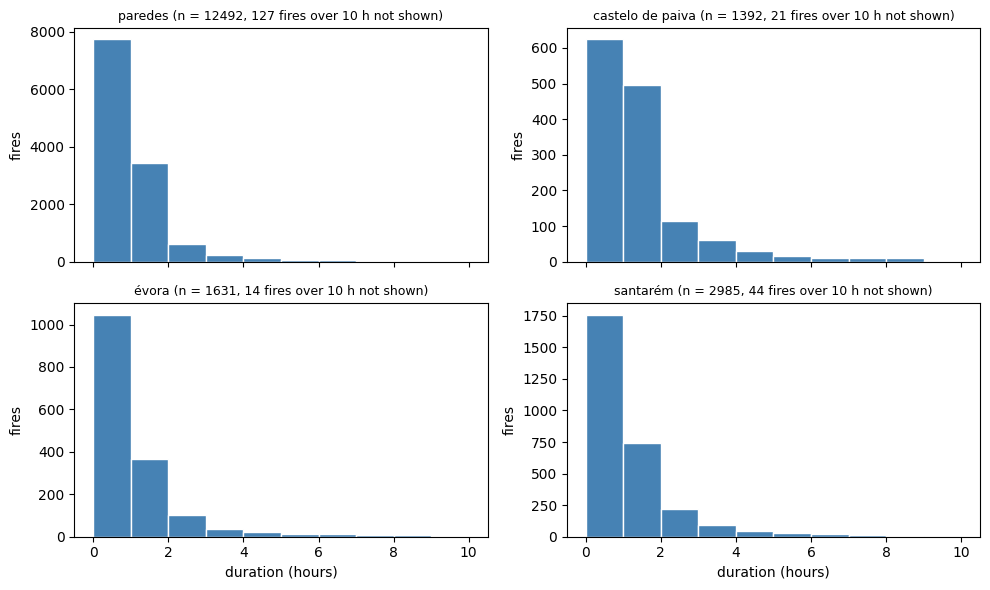

In [35]:
# histogram of the duration (up to 10 hours) in each municipality
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for ax, m in zip(axes.ravel(), MUNICIPALITIES):
    x = q24.loc[q24["Concelho"] == m, "Duracao_Horas"]
    ax.hist(x, bins=range(0, 11), color="steelblue", edgecolor="white")
    ax.set_title(f"{m} (n = {len(x)}, {(x > 10).sum()} fires over 10 h not shown)", fontsize=9)
    ax.set_ylabel("fires")
axes[1, 0].set_xlabel("duration (hours)")
axes[1, 1].set_xlabel("duration (hours)")
plt.tight_layout()
plt.show()

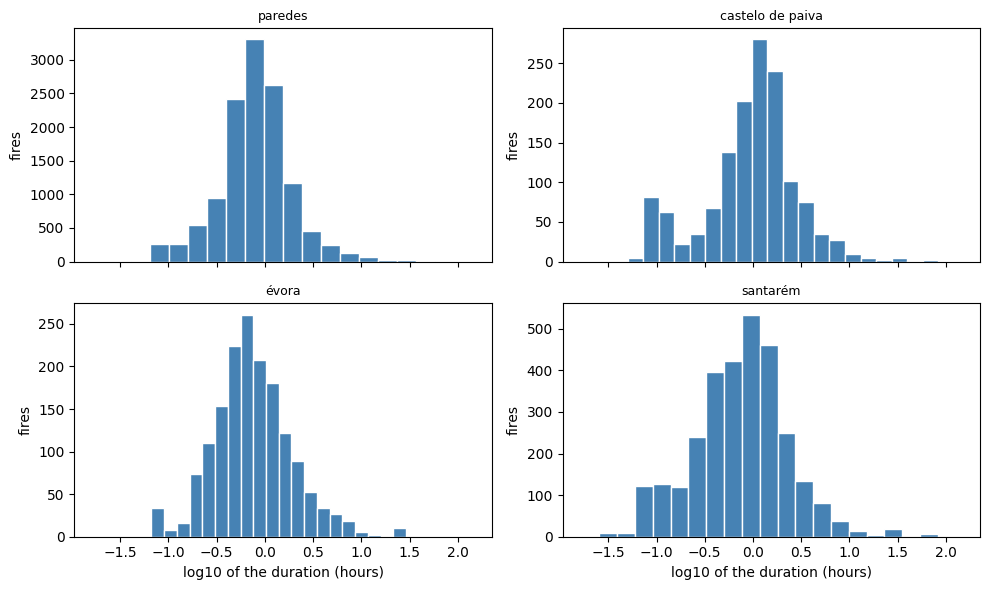

In [36]:
# same, with the logarithm of the duration
import numpy as np

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for ax, m in zip(axes.ravel(), MUNICIPALITIES):
    x = np.log10(q24.loc[q24["Concelho"] == m, "Duracao_Horas"])
    ax.hist(x, bins=20, color="steelblue", edgecolor="white")
    ax.set_title(m, fontsize=9)
    ax.set_ylabel("fires")
axes[1, 0].set_xlabel("log10 of the duration (hours)")
axes[1, 1].set_xlabel("log10 of the duration (hours)")
plt.tight_layout()
plt.show()

In [37]:
# skewness: 0 means symmetric, the higher the more the tail goes to the right
skew = pd.DataFrame({
    "duration": q24.groupby("Concelho")["Duracao_Horas"].skew(),
    "log10 of duration": np.log10(q24["Duracao_Horas"]).groupby(q24["Concelho"]).skew()})
skew.round(2)

C:\Users\Maria Mota\AppData\Local\Temp\ipykernel_22812\889858161.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  "duration": q24.groupby("Concelho")["Duracao_Horas"].skew(),
C:\Users\Maria Mota\AppData\Local\Temp\ipykernel_22812\889858161.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  "log10 of duration": np.log10(q24["Duracao_Horas"]).groupby(q24["Concelho"]).skew()})


,duration,log10 of duration
Concelho,,
castelo de paiva,12.64,-0.24
paredes,18.79,0.29
santarém,11.26,0.11
évora,7.90,0.45


### How many long fires if the limit were lower

Question 2 is about fires of 24 hours or more, but only 79 fires reach it. Here we only look at how the counts would change with a lower limit, to see how much margin we have. We don't change `IncSup24horas`.

In [38]:
# fires with a duration of at least X hours in each municipality,
# and the smallest expected count of the chi-square test
from scipy.stats import chi2_contingency

rows = []
for hours in range(24, 1, -1):
    long_fire = q24["Duracao_Horas"] >= hours
    table = pd.crosstab(q24["Concelho"], long_fire)
    expected = chi2_contingency(table)[3]

    row = table[True].to_dict()
    row["total"] = long_fire.sum()
    row["% of fires"] = round(long_fire.mean() * 100, 2)
    row["smallest expected"] = round(expected.min(), 1)
    rows.append(pd.Series(row, name=f"{hours} h or more"))

pd.DataFrame(rows)

,castelo de paiva,paredes,santarém,évora,total,% of fires,smallest expected
24 h or more,8.0,36.0,26.0,9.0,79.0,0.43,5.9
23 h or more,8.0,38.0,26.0,10.0,82.0,0.44,6.2
22 h or more,8.0,39.0,26.0,10.0,83.0,0.45,6.2
21 h or more,8.0,40.0,26.0,10.0,84.0,0.45,6.3
20 h or more,9.0,42.0,26.0,10.0,87.0,0.47,6.5
19 h or more,9.0,46.0,27.0,10.0,92.0,0.50,6.9
18 h or more,9.0,51.0,28.0,10.0,98.0,0.53,7.4
17 h or more,13.0,56.0,30.0,10.0,109.0,0.59,8.2
16 h or more,13.0,64.0,30.0,10.0,117.0,0.63,8.8
15 h or more,13.0,68.0,31.0,10.0,122.0,0.66,9.2


What we see:

- With 24 hours, the smallest expected count is 5.9, so the chi-square condition (at least 5 expected fires in each cell) holds, but with little margin: Castelo de Paiva has only 8 fires of 24 hours or more.
- A lower limit gives more margin, but it changes the question. With 24 hours Santarém has the highest share of long fires (0.87%). From 6 hours down it is Castelo de Paiva (3.81% with 6 hours, 19.5% with 2 hours).
- With a low limit the long fires stop being rare (2 hours or more are 12% of the fires), and question 2 starts measuring almost the same thing as question 4 (duration by municipality).

We keep 24 hours: the condition of the test holds and it is the official SGIF variable (`IncSup24horas`).

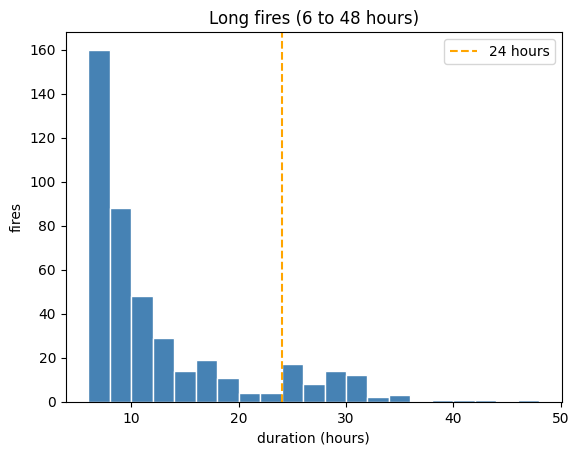

In [39]:
# the long part of the distribution (6 to 48 hours), the four municipalities together
long_part = q24.loc[q24["Duracao_Horas"].between(6, 48), "Duracao_Horas"]

fig, ax = plt.subplots()
ax.hist(long_part, bins=range(6, 50, 2), color="steelblue", edgecolor="white")
ax.axvline(24, color="orange", ls="--", label="24 hours")
ax.set_xlabel("duration (hours)")
ax.set_ylabel("fires")
ax.set_title("Long fires (6 to 48 hours)")
ax.legend()
plt.show()

We keep the long fires (up to 144 hours in Paredes). They are outliers, but real ones: big fires that tell us about specific events. Duration is very skewed (median around 1 hour), so the log scale is needed to see anything.

## Questions 3 and 5: time to first intervention

There is no column with this time, we compute it from the alert and the first intervention.

In [40]:
data["time_first_intervention_min"] = (data["DataHora_PrimeiraIntervencao"] - data["DataHoraAlerta"]).dt.total_seconds() / 60
data["time_first_intervention_min"].describe()

count    2.827060e+05
mean     3.843065e+01
std      1.285912e+04
min      0.000000e+00
25%      7.000000e+00
50%      1.100000e+01
75%      1.600000e+01
max      6.837131e+06
Name: time_first_intervention_min, dtype: float64

In [41]:
# the first intervention date only exists from 2008
data.groupby("Ano")["time_first_intervention_min"].count()

Ano
2001        0
2002        0
2003        0
2004        0
2005        0
2006       51
2007        1
2008    16042
2009    25738
2010    23768
2011    29532
2012    25352
2013    23129
2014     9388
2015    19643
2016    16104
2017    21006
2018    12274
2019    10831
2020     9595
2021     8167
2022    10350
2023     7514
2024     6122
2025     8099
Name: time_first_intervention_min, dtype: int64

Before 2008 there is almost no intervention date (51 fires in 2006, 1 in 2007), so for question 3 the "before" period is really 2008 to 2017.

In [42]:
# intervention after extinction is not possible, and time = 0 looks like the alert time copied
data["DataHora_Extincao"] = pd.to_datetime(
    data["DataHora_Extincao"], errors="coerce"
)

after_ext = data["DataHora_PrimeiraIntervencao"] > data["DataHora_Extincao"]
zero = data["time_first_intervention_min"] == 0
print("intervention after extinction:", after_ext.sum())
print("time = 0:                     ", zero.sum())

intervention after extinction: 3987
time = 0:                      2400


These fires are fine for the other questions, so we don't change `data`. We only leave them out of `q3` and `q5`:

- Intervention after the extinction is not possible. 20 of them also have the year or month wrong (a fire from 2008 with the intervention in 2021).
- Time = 0 is probably the alert time copied as intervention time: 64% were reported by the public (`Populares`), against 57% in the rest.
- Burned area = 0 (only for `q5`): almost all are from 2008-2012 and these fires lasted hours, so it looks like a recording habit of those years.

We keep the fires with a time over 24 hours. They are 62 fires, all of them 24 hours plus a few minutes, which could be a date error, but we can't be sure and we have no reason to remove them.

In [43]:
# how many fires have each problem, by period (fires from 2008 with an intervention date)
from_2008 = data[(data["Ano"] >= 2008) & data["time_first_intervention_min"].notna()]
rows = from_2008.index

rare = pd.DataFrame({
    "fires": from_2008.groupby("period", observed=True).size(),
    "intervention after extinction": after_ext[rows].groupby(from_2008["period"], observed=True).sum(),
    "time = 0": zero[rows].groupby(from_2008["period"], observed=True).sum(),
    "time over 24 h (kept)": ((from_2008["time_first_intervention_min"] > 24 * 60) & ~after_ext[rows]).groupby(from_2008["period"], observed=True).sum(),
    "area = 0": (from_2008["AreaTotal_ha"] == 0).groupby(from_2008["period"], observed=True).sum()})
rare

,fires,intervention after extinction,time = 0,time over 24 h (kept),area = 0
period,,,,,
after,72952,888,426,4,210
before,209702,3098,1973,58,6237


In [44]:
# Q3: fires from 2008 with a real time to first intervention
# (not missing, not 0 and not after the extinction)
q3 = data[
    (data["Ano"] >= 2008)
    & (data["time_first_intervention_min"] > 0)
    & ~after_ext
].copy()

# Q5: the same fires, leaving out the ones with burned area = 0
q5 = q3[q3["AreaTotal_ha"] > 0].copy()

print("Q3 observations:", len(q3))
print("Q5 observations:", len(q5))

Q3 observations: 276269
Q5 observations: 270096


In [45]:
q3.groupby("period", observed=True)["time_first_intervention_min"].agg(["count", "median", "mean"])

,count,median,mean
period,,,
after,71638,13.0,16.102557
before,204631,10.0,13.199022


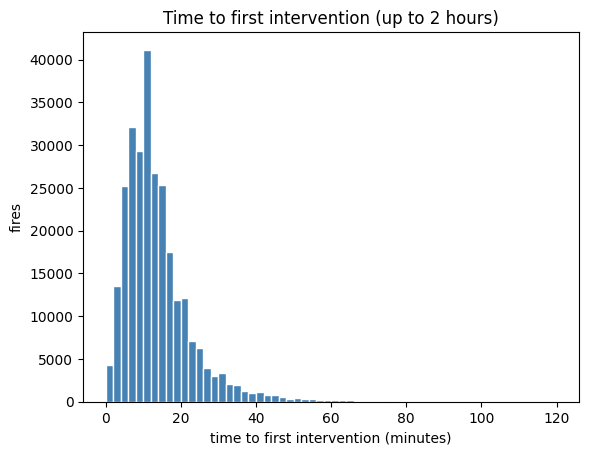

In [46]:
fig, ax = plt.subplots()
ax.hist(q3["time_first_intervention_min"], bins=range(0, 121, 2), color="steelblue", edgecolor="white")
ax.set_xlabel("time to first intervention (minutes)")
ax.set_ylabel("fires")
ax.set_title("Time to first intervention (up to 2 hours)")
plt.show()

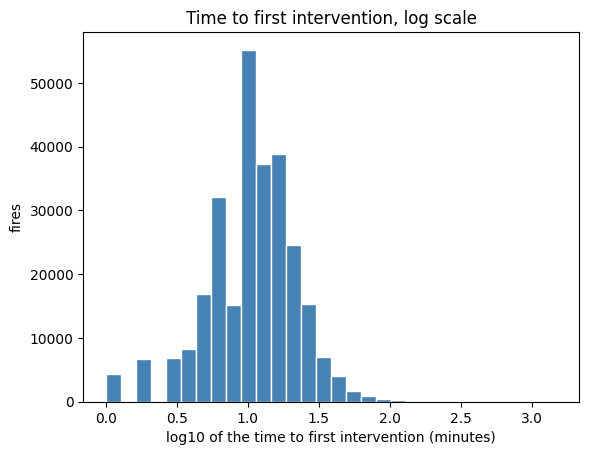

skewness:          43.3
skewness of log10: -0.39


In [47]:
# same with the logarithm of the time
import numpy as np

fig, ax = plt.subplots()
ax.hist(np.log10(q3["time_first_intervention_min"]), bins=30, color="steelblue", edgecolor="white")
ax.set_xlabel("log10 of the time to first intervention (minutes)")
ax.set_ylabel("fires")
ax.set_title("Time to first intervention, log scale")
plt.show()

print("skewness:         ", round(q3["time_first_intervention_min"].skew(), 1))
print("skewness of log10:", round(np.log10(q3["time_first_intervention_min"]).skew(), 2))

In [48]:
q5[["time_first_intervention_min", "AreaTotal_ha"]].describe()

,time_first_intervention_min,AreaTotal_ha
count,270096.000000,270096.000000
mean,13.987201,7.743308
std,25.168162,289.917945
min,1.000000,0.000001
25%,7.000000,0.010000
50%,11.000000,0.050000
75%,17.000000,0.500000
max,1488.000000,65478.286936


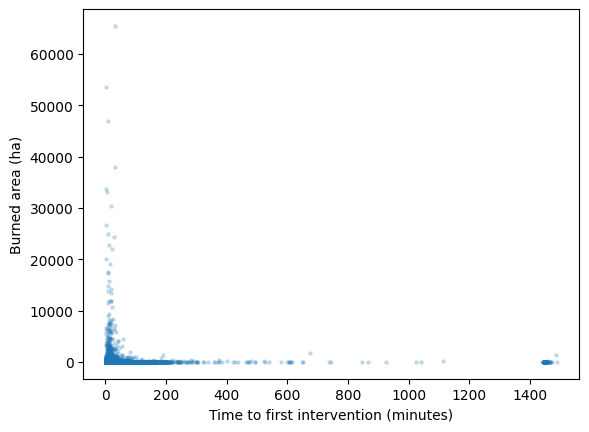

In [49]:
plt.scatter(
    q5["time_first_intervention_min"],
    q5["AreaTotal_ha"],
    alpha=0.2,
    s=5
)

plt.xlabel("Time to first intervention (minutes)")
plt.ylabel("Burned area (ha)")
plt.show()

## Questions 3 and 5: analysis datasets

We restrict these analyses to 2008–2025 because first-intervention
timestamps are almost entirely missing before 2008.
We use the intervention times retained after the cleaning above.

In [50]:
print("Q3 observations:", len(q3))
print("Q5 observations:", len(q5))

Q3 observations: 276269
Q5 observations: 270096


In [51]:
q5[["time_first_intervention_min", "AreaTotal_ha"]].describe()

,time_first_intervention_min,AreaTotal_ha
count,270096.000000,270096.000000
mean,13.987201,7.743308
std,25.168162,289.917945
min,1.000000,0.000001
25%,7.000000,0.010000
50%,11.000000,0.050000
75%,17.000000,0.500000
max,1488.000000,65478.286936


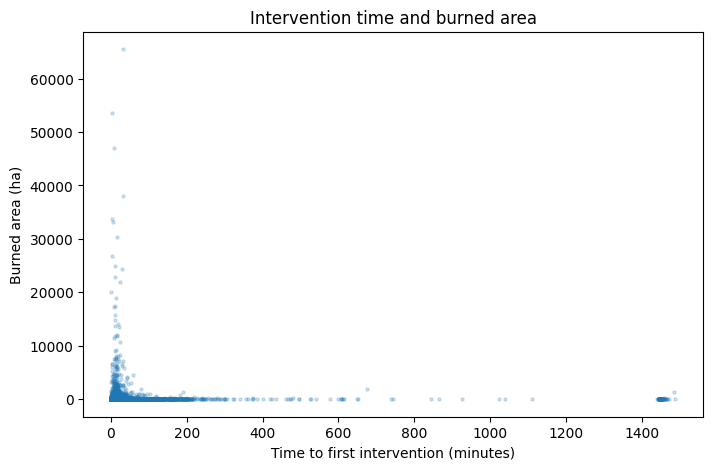

In [52]:
plt.figure(figsize=(8, 5))

plt.scatter(
    q5["time_first_intervention_min"],
    q5["AreaTotal_ha"],
    alpha=0.2,
    s=5
)

plt.xlabel("Time to first intervention (minutes)")
plt.ylabel("Burned area (ha)")
plt.title("Intervention time and burned area")
plt.show()

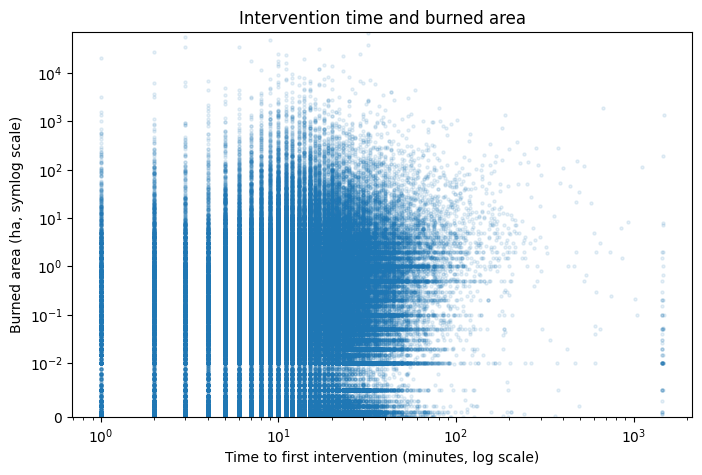

In [53]:
plt.figure(figsize=(8, 5))

plt.scatter(
    q5["time_first_intervention_min"],
    q5["AreaTotal_ha"],
    alpha=0.1,
    s=5
)

plt.xscale("log")
plt.yscale("symlog", linthresh=0.01)

plt.xlabel("Time to first intervention (minutes, log scale)")
plt.ylabel("Burned area (ha, symlog scale)")
plt.title("Intervention time and burned area")
plt.ylim(bottom=0)
plt.show()

## Sample size check

How many fires we have in each question after the cleaning.

In [54]:
print("Q1: fires by period and cause")
display(pd.crosstab(q1["period"], q1["TipoCausa"].astype(str), margins=True))

print("Q2: fires by municipality and duration (0 = less than 24 h, 1 = 24 h or more)")
display(pd.crosstab(q24["Concelho"], q24["IncSup24horas"], margins=True))

print("Q3: fires by period")
display(q3["period"].value_counts())

print("Q4: fires by municipality")
display(q24["Concelho"].value_counts())

print("Q5: fires")
print(len(q5))

Q1: fires by period and cause


TipoCausa,Intencional,Negligente,All
period,,,
after,13872,26201,40073
before,34141,57459,91600
All,48013,83660,131673


Q2: fires by municipality and duration (0 = less than 24 h, 1 = 24 h or more)


IncSup24horas,0,1,All
Concelho,,,
castelo de paiva,1384,8,1392
paredes,12456,36,12492
santarém,2959,26,2985
évora,1622,9,1631
All,18421,79,18500


Q3: fires by period


period
before    204631
after      71638
Name: count, dtype: int64

Q4: fires by municipality


Concelho
paredes             12492
santarém             2985
évora                1631
castelo de paiva     1392
Name: count, dtype: int64

Q5: fires
270096


We have enough fires for every question. The smallest group is Castelo de Paiva with 1392 fires (questions 2 and 4).

Question 2 has few fires of 24 hours or more (8 in Castelo de Paiva and 9 in Évora). It is a limit of the data, and the condition of the test is checked in question 2.

### What we cleaned for each question

| Question | What we did |
|---|---|
| All | Municipality names in lower case (379 to 278 names), 1 fire without municipality removed, `Distrito` dropped, `Codigo_SGIF` as text. |
| Q1 | Only the fires with cause `Negligente` or `Intencional` (131,673). The other causes and the missing ones are left out, we don't impute a cause. All the years are used: before = 2001-2017, after = 2018-2025. |
| Q2 and Q4 | Only the four municipalities, leaving out the fires with missing duration (10) or duration 0 (21). The long fires are kept. 18,500 fires. |
| Q3 | Only the fires from 2008, because before there is no intervention date. Left out: intervention after the extinction (3,986) and time = 0 (2,399). The fires with a time over 24 hours are kept. 276,269 fires. |
| Q5 | The same fires as Q3, leaving out the ones with burned area = 0 (6,173). 270,096 fires. |

These exclusions don't change `data`: each question has its own dataset (`q1`, `q24`, `q3` and `q5`).

## Save the clean data

We save `data` and the dataset of each question in parquet, so we don't have to read the Excel files again.

In [56]:
# q1 e q24 foram criados antes da conversão de DataHora_Extincao para datetime
q1 = q1.assign(DataHora_Extincao=pd.to_datetime(q1["DataHora_Extincao"], errors="coerce"))
q24 = q24.assign(DataHora_Extincao=pd.to_datetime(q24["DataHora_Extincao"], errors="coerce"))

data.to_parquet("Registos_Incendios_SGIF_2001_2025_clean.parquet", index=False)
q1.to_parquet("Registos_Incendios_SGIF_q1.parquet", index=False)
q24.to_parquet("Registos_Incendios_SGIF_q24.parquet", index=False)
q3.to_parquet("Registos_Incendios_SGIF_q3.parquet", index=False)
q5.to_parquet("Registos_Incendios_SGIF_q5.parquet", index=False)


In [57]:
# read them back to check the shape and the types
files = {"2001_2025_clean": data, "q1": q1, "q24": q24, "q3": q3, "q5": q5}

for name, df in files.items():
    back = pd.read_parquet(f"Registos_Incendios_SGIF_{name}.parquet")
    print(name, df.shape, back.shape, "same types:", (df.dtypes == back.dtypes).all())

2001_2025_clean (497477, 12) (497477, 12) same types: True
q1 (131673, 11) (131673, 11) same types: True
q24 (18500, 11) (18500, 11) same types: True
q3 (276269, 12) (276269, 12) same types: True
q5 (270096, 12) (270096, 12) same types: True


## Question 1: Comparison of wildfire causes between periods

Does the proportion of negligent versus intentional wildfires differ
between 2001–2017 and 2018–2025 in mainland Portugal?

This analysis includes only fires classified as negligent or intentional.

### Hypotheses

Let p_before and p_after represent the population proportions of negligent
fires among fires classified as negligent or intentional in each period.

- H₀: p_before = p_after
- H₁: p_before ≠ p_after

We use a two-sided two-proportion z-test at a significance level of α = 0.05.

### Conditions and assumptions

**Independence**

Each record represents a separate fire, and the two periods contain
different fires, so the observations are not paired. Independence within
and between periods is assumed. Shared temporal and geographical factors
may limit this assumption.

The data are administrative records rather than random samples.
Generalisation is also limited by missing and unknown causes,
particularly in the earlier period.

**Success–failure condition**

Under H₀, both periods share the same population proportion.
We estimate it using the pooled sample proportion.

Each period must have at least 10 expected negligent fires and
10 expected intentional fires under H₀. We check this below.

In [58]:
# Count negligent and intentional fires in each period.

cause_table = pd.crosstab(q1["period"], q1["TipoCausa"])
cause_table

TipoCausa,Intencional,Negligente
period,,
after,13872,26201
before,34141,57459


### Checking the success–failure condition

The pooled proportion of negligent fires is:

p_pooled = (57,459 + 26,201) / (91,600 + 40,073)
         = 83,660 / 131,673
         ≈ 0.63536.

Expected counts equal each period's total multiplied by the pooled
proportion for the corresponding cause.

| Period | Expected negligent | Expected intentional |
|---|---|---|
| Before | 91,600 × 0.63536 ≈ 58,199 | 91,600 × 0.36464 ≈ 33,401 |
| After | 40,073 × 0.63536 ≈ 25,461 | 40,073 × 0.36464 ≈ 14,612 |

All four expected counts exceed 10, satisfying the success-failure condition.

In [59]:
from statsmodels.stats.proportion import proportions_ztest

# Count fires by period and cause.
table = pd.crosstab(q1["period"], q1["TipoCausa"])

# Keep the same order for both: before, after.
counts = table.loc[["before", "after"], "Negligente"]
totals = table.loc[
    ["before", "after"], ["Negligente", "Intencional"]
].sum(axis=1)

# Calculate and display the observed percentages.
proportions = counts / totals
print("Negligent fires (%):")
print((proportions * 100).round(2))

# Calculate the change in percentage points.
difference_pp = (proportions["after"] - proportions["before"]) * 100
print(f"\nDifference (after − before): {difference_pp:.2f} percentage points")

# Compare the two population proportions.
z_stat, p_value = proportions_ztest(
    counts, totals, alternative="two-sided"
)

print("\nz-statistic:", z_stat)
print("p-value:", p_value)

Negligent fires (%):
period
before    62.73
after     65.38
dtype: float64

Difference (after − before): 2.66 percentage points

z-statistic: -9.209791568067667
p-value: 3.26758802987174e-20


### Confidence interval for the difference in proportions

The test tells us whether the proportions differ. The confidence interval
tells us by how much.

CI = (p̂_after − p̂_before) ± z* × SE

SE = √( p̂_before(1 − p̂_before)/n_before + p̂_after(1 − p̂_after)/n_after )

Unlike the test, the interval does not assume H₀, so the standard error
uses each period's own proportion instead of the pooled one. For the same
reason, the success-failure condition uses the observed counts:
at least 10 negligent and 10 intentional fires in each period.

In [60]:
from scipy.stats import norm
import numpy as np

# Confidence interval for p_after - p_before (95%).
# The CI uses each group's own proportion (not the pooled one).
confidence = 0.95

table = pd.crosstab(q1["period"], q1["TipoCausa"])
x_before = table.loc["before", "Negligente"]
x_after = table.loc["after", "Negligente"]
n_before = table.loc["before", ["Negligente", "Intencional"]].sum()
n_after = table.loc["after", ["Negligente", "Intencional"]].sum()

p_before = x_before / n_before
p_after = x_after / n_after

# Success-failure condition for the CI: at least 10 observed successes and failures.
print("Observed successes and failures:")
print("before:", x_before, n_before - x_before)
print("after: ", x_after, n_after - x_after)

Observed successes and failures:
before: 57459 34141
after:  26201 13872


In [61]:
difference = p_after - p_before
se = np.sqrt(p_before * (1 - p_before) / n_before + p_after * (1 - p_after) / n_after)
z_crit = norm.ppf(1 - (1 - confidence) / 2)

lower = difference - z_crit * se
upper = difference + z_crit * se

print(f"\nDifference (after − before): {difference * 100:.2f} percentage points")
print(f"SE: {se:.5f}, z*: {z_crit:.3f}")
print(f"{confidence:.0%} CI: [{lower * 100:.2f}, {upper * 100:.2f}] percentage points")


Difference (after − before): 2.66 percentage points
SE: 0.00286, z*: 1.960
95% CI: [2.09, 3.22] percentage points


### Results and conclusion

The proportion of negligent fires was 62.73% in 2001–2017 and
65.38% in 2018–2025, an increase of approximately 2.66 percentage points.

The two-sided two-proportion z-test gave z = −9.21 and
p = 3.27 × 10⁻²⁰. At the 5% significance level, we reject H₀.

There is statistically significant evidence that the proportion of
negligent fires among fires classified as negligent or intentional
differs between the periods, with a higher proportion after 2017.

The 95% confidence interval for the difference (after − before) is
[2.09, 3.22] percentage points. Each period has far more than 10
observed negligent and intentional fires, so the success-failure
condition for the interval holds. The interval does not contain 0,
which agrees with the test, and shows that the increase is small:
between 2.09 and 3.22 percentage points.

Although statistically significant, the observed difference is modest.
The comparison excludes other and missing causes; cause information
was substantially less complete in the earlier period, which limits
generalisation to all wildfires.

### Question 1 with random samples

Here we treat the cleaned data of question 1 (`q1`) as the population.
The difference computed with all the data, 2.66 percentage points, is
therefore the true difference.

We draw random samples of 30, 100, 500, 2000 and 4000 fires from each
period (without replacement, 1000 samples per size). In each sample we
compute the 95% confidence interval and the two-proportion z-test, as
we did with all the data, and we check how often the interval contains
the true difference and how often the test rejects H₀.

The largest size, 4000, is just under 10% of the fires after 2017
(40,073), so the 10% condition holds for every size.

In [ ]:
import numpy as np

# Population: True = negligent, False = intentional, for each period.
pop_before = (q1.loc[q1["period"] == "before", "TipoCausa"] == "Negligente").to_numpy()
pop_after = (q1.loc[q1["period"] == "after", "TipoCausa"] == "Negligente").to_numpy()

true_diff = pop_after.mean() - pop_before.mean()   # .mean(), mas o que está a calcular são proporções!

print("population before:", len(pop_before))
print("population after: ", len(pop_after))
print(f"true difference (after − before): {true_diff * 100:.2f} percentage points")

population before: 91600
population after:  40073
true difference (after − before): 2.66 percentage points


#### One sample

The function `one_sample` does, for one sample size `n`, what we did
with all the data:

1. Draws a random sample of `n` fires from each period, without replacement.
2. Computes the difference in the proportion of negligent fires (after − before)
   and its 95% confidence interval, with the unpooled standard error.
3. Checks the success-failure condition: at least 10 observed negligent and
   10 observed intentional fires in each period.
4. Runs the two-proportion z-test (pooled) at α = 0.05.

It returns the interval, its width, whether it contains the true difference
(`covers`), whether the condition holds (`condition`) and whether the test
rejects H₀ (`reject`).

We run it once with n = 30 to see one result before repeating it many times.

In [69]:
from scipy.stats import norm
from statsmodels.stats.proportion import proportions_ztest

def one_sample(n, rng, confidence=0.95, alpha=0.05):
    # Random sample of n fires from each period, without replacement.
    s_before = rng.choice(pop_before, size=n, replace=False)
    s_after = rng.choice(pop_after, size=n, replace=False)

    x_before, x_after = s_before.sum(), s_after.sum()
    p_before, p_after = x_before / n, x_after / n

    # Confidence interval (unpooled SE), as with all the data.
    diff = p_after - p_before
    se = np.sqrt(p_before * (1 - p_before) / n + p_after * (1 - p_after) / n)
    z_crit = norm.ppf(1 - (1 - confidence) / 2)
    lower, upper = diff - z_crit * se, diff + z_crit * se

    # Success-failure condition: at least 10 observed successes and failures.
    condition = min(x_before, n - x_before, x_after, n - x_after) >= 10

    # Two-proportion z-test (pooled), as with all the data.
    z_stat, p_value = proportions_ztest([x_before, x_after], [n, n])

    return {"n": n, "diff": diff, "lower": lower, "upper": upper,
            "width": upper - lower,
            "covers": lower <= true_diff <= upper,
            "condition": condition,
            "reject": p_value < alpha}

rng = np.random.default_rng(42)
one_sample(30, rng)

{'n': 30,
 'diff': np.float64(-0.06666666666666665),
 'lower': np.float64(-0.29795841097346454),
 'upper': np.float64(0.1646250776401312),
 'width': np.float64(0.4625834886135958),
 'covers': np.True_,
 'condition': np.False_,
 'reject': np.False_}

In [70]:
SAMPLE_SIZES = [30, 100, 1000, 4000]
REPETITIONS = 1000

rng = np.random.default_rng(42)
results_q1 = pd.DataFrame(
    [one_sample(n, rng) for n in SAMPLE_SIZES for _ in range(REPETITIONS)]
)

# One row per sample size.
summary_samples_q1 = results_q1.groupby("n").agg(
    mean_width_pp=("width", lambda w: w.mean() * 100),
    coverage_pct=("covers", lambda c: c.mean() * 100),
    reject_H0_pct=("reject", lambda r: r.mean() * 100),
    condition_ok_pct=("condition", lambda c: c.mean() * 100),
).round(1)

summary_samples_q1

,mean_width_pp,coverage_pct,reject_H0_pct,condition_ok_pct
n,,,,
30,47.6,93.3,6.2,45.0
100,26.4,93.5,6.8,100.0
1000,8.4,96.1,23.4,100.0
4000,4.2,95.1,69.7,100.0


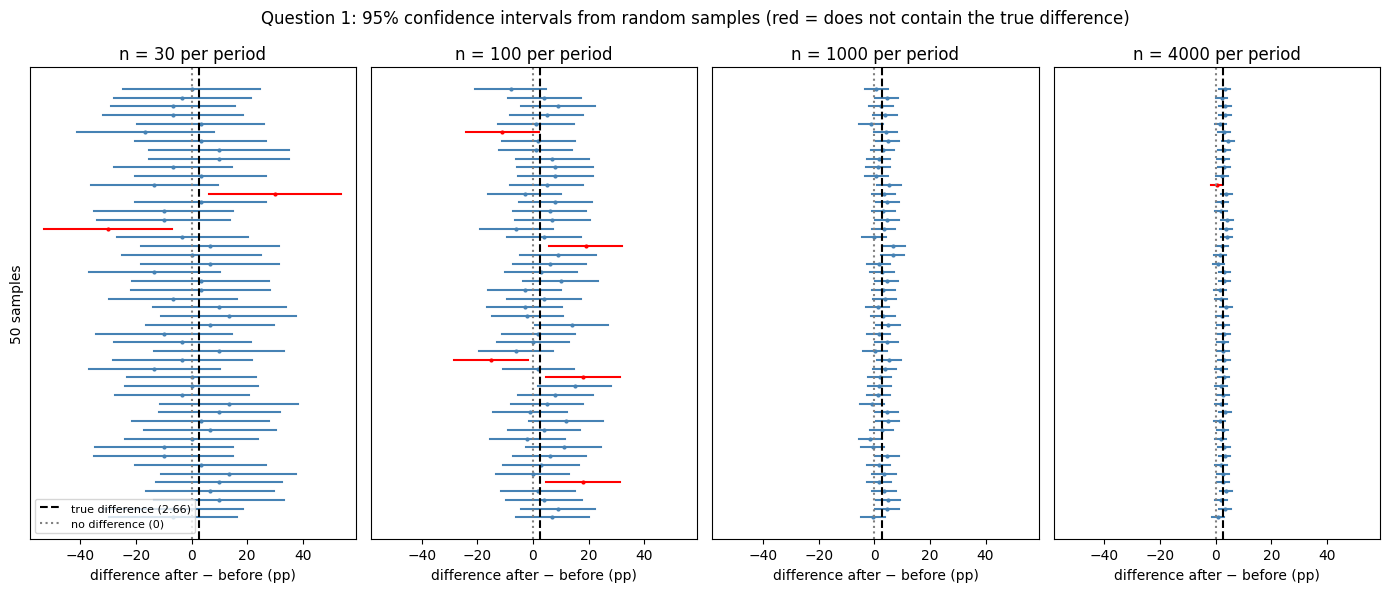

In [71]:
# 95% confidence intervals of the first 50 samples of each size.
# Red = the interval does not contain the true difference.
N_SHOWN = 50

fig, axes = plt.subplots(1, len(SAMPLE_SIZES), figsize=(14, 6), sharex=True, sharey=True)

for ax, n in zip(axes, SAMPLE_SIZES):
    shown = results_q1[results_q1["n"] == n].head(N_SHOWN).reset_index(drop=True)
    for i, row in shown.iterrows():
        color = "steelblue" if row["covers"] else "red"
        ax.plot([row["lower"] * 100, row["upper"] * 100], [i, i], color=color, lw=1.5)
        ax.plot(row["diff"] * 100, i, "o", color=color, ms=2)
    ax.axvline(true_diff * 100, color="black", ls="--", label="true difference (2.66)")
    ax.axvline(0, color="gray", ls=":", label="no difference (0)")
    ax.set_title(f"n = {n} per period")
    ax.set_xlabel("difference after − before (pp)")
    ax.set_yticks([])

axes[0].set_ylabel(f"{N_SHOWN} samples")
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle("Question 1: 95% confidence intervals from random samples "
             "(red = does not contain the true difference)")
plt.tight_layout()
plt.show()

What we see (first 50 samples from the 1000 total, of each size):

- The intervals get narrower from left to right as the sample grows.
- With 30 and 100 fires, almost all intervals cross 0, so the test does not reject H₀.
- With 4000 fires, most intervals lie entirely to the right of 0.

#### Results with random samples

| Sample size per period | Mean CI width (pp) | CIs containing 2.66 (%) | Tests rejecting H₀ (%) | Samples meeting the condition (%) |
|---|---|---|---|---|
| 30 | 47.6 | 93.3 | 6.2 | 45.0 |
| 100 | 26.4 | 93.5 | 6.8 | 100.0 |
| 1000 | 8.4 | 96.1 | 23.4 | 100.0 |
| 4000 | 4.2 | 95.1 | 69.7 | 100.0 |

- **Width:** the interval gets narrower as the sample grows. With 30 fires per
  period it is about 48 percentage points wide, far too wide to say anything
  about a difference of 2.66. With 4000 fires it is 4.2 points wide.
- **Coverage:** with 1000 and 4000 fires, about 95% of the intervals contain
  the true difference, as expected for a 95% interval. With 30 and 100 fires
  it is slightly lower (about 93%).
- **Test:** the true difference is not 0, but the test only detects it in 6% to
  7% of the samples of 30 and 100 fires, 23% with 1000 and 70% with 4000.
- **Condition:** with 30 fires per period, only 45% of the samples have at least
  10 negligent and 10 intentional fires in each period, so in most of them the
  interval and the test should not be used.

With all the data the difference was clearly significant (p ≈ 10⁻²⁰). The
samples show that this comes mainly from the very large number of fires:
the difference is real but small, and with samples of a few hundred fires
it would usually not be detected.

**What the samples add:** the difference is real but small. It is only detected
reliably with thousands of fires per period, so the very small p-value obtained
with all the data comes mainly from the size of the data.

### Exam reference: confidence interval for one proportion

Use it to estimate a single population proportion p, for example
the proportion of negligent fires in one period.

#### Formula

CI = p̂ ± z* × SE, with SE = √( p̂(1 − p̂) / n )

- p̂ = x / n: observed proportion (x successes in n observations)
- z*: critical value, 1.96 for 95% (`norm.ppf(1 - (1 - confidence) / 2)`)

#### Conditions checklist

**Independence**

Observations are independent. With random sampling without replacement,
the sample is less than 10% of the population.

**Success-failure condition**

At least 10 **observed** successes and 10 observed failures:
x ≥ 10 and n − x ≥ 10.
(For a confidence interval we use the observed counts; for a test
we use the expected counts under H₀.)

#### Interpretation

"We are 95% confident that the population proportion of [success]
is between [lower] and [upper]."

In [62]:
from scipy.stats import norm
import numpy as np

# REUSABLE TEMPLATE — CONFIDENCE INTERVAL FOR ONE PROPORTION

# CHANGE THESE FOR A NEW DATASET
df = q1[q1["period"] == "after"]     # the group to estimate
outcome_column = "TipoCausa"
success = "Negligente"

confidence = 0.95

# KEEP THE CODE BELOW THE SAME
values = df[outcome_column].dropna()
n = len(values)
x = (values == success).sum()
p_hat = x / n

# Success-failure condition: at least 10 observed successes and failures.
print("successes:", x, " failures:", n - x)
print("condition holds:", x >= 10 and n - x >= 10)

se = np.sqrt(p_hat * (1 - p_hat) / n)
z_crit = norm.ppf(1 - (1 - confidence) / 2)

lower = p_hat - z_crit * se
upper = p_hat + z_crit * se

print(f"\np_hat: {p_hat:.4f}, n: {n}")
print(f"SE: {se:.5f}, z*: {z_crit:.3f}")
print(f"{confidence:.0%} CI: [{lower:.4f}, {upper:.4f}]")

successes: 26201  failures: 13872
condition holds: True

p_hat: 0.6538, n: 40073
SE: 0.00238, z*: 1.960
95% CI: [0.6492, 0.6585]


### Exam reference: reusable two-proportion z-test


Adapt the dataset, column names, group labels, outcome labels,
alternative hypothesis and significance level (`alpha`) before running.
Check the conditions for the new data.

#### Hypotheses

Let p₁ and p₂ represent the population proportions of the outcome
defined as "success" in groups 1 and 2.

- H₀: p₁ = p₂
- H₁: p₁ ≠ p₂ — use `alternative="two-sided"`.

For a one-sided test, adapt H₁ and the code:

- H₁: p₁ > p₂ — use `alternative="larger"`.
- H₁: p₁ < p₂ — use `alternative="smaller"`.

#### Conditions checklist

**Binary outcome**

The same success/failure outcome is measured in two groups.

**Independence**

Observations are independent within and between groups.
The data are not paired.

**Data collection**

Explain random sampling or random assignment, if applicable.
Otherwise, acknowledge limitations to generalisation.

For sampling without replacement, check that each sample is less
than 10% of its population.

**Success–failure condition**

Let x₁ and x₂ be the numbers of successes, and n₁ and n₂ the total
observations in each group.

Under H₀: p₁ = p₂, calculate the pooled proportion:

p_pool = (x₁ + x₂) / (n₁ + n₂)

Check that all four expected counts are at least 10:

| Group | Expected successes | Expected failures |
|---|---|---|
| 1 | n₁ × p_pool ≥ 10 | n₁ × (1 − p_pool) ≥ 10 |
| 2 | n₂ × p_pool ≥ 10 | n₂ × (1 − p_pool) ≥ 10 |

Normality of the original data, equal group sizes and equal population
variances are not required.

In [63]:
# REUSABLE TEMPLATE — TWO-PROPORTION Z-TEST

from statsmodels.stats.proportion import proportions_ztest

# CHANGE THESE FOR A NEW DATASET
df = q1
group_column = "period"
outcome_column = "TipoCausa"

group1 = "before"
group2 = "after"

success = "Negligente"
failure = "Intencional"

alpha = 0.05  # Change to the significance level given in the question.

# Choose ONE setting according to the question:
# "two-sided" → H1: p1 ≠ p2
# "larger"    → H1: p1 > p2
# "smaller"   → H1: p1 < p2
# Here, p1 = proportion in group1; p2 = proportion in group2.
alternative = "two-sided"

# KEEP THE CODE BELOW THE SAME
# Count the two outcomes in each group.
table = pd.crosstab(df[group_column], df[outcome_column])

table = table.reindex(
    index=[group1, group2],
    columns=[success, failure],
    fill_value=0
)

counts = table[success]
totals = table.sum(axis=1)

# Observed percentages of the outcome defined as "success".
proportions = counts / totals
print("Success (%):")
print((proportions * 100).round(2))

# Descriptive difference: group2 minus group1.
difference_pp = (proportions[group2] - proportions[group1]) * 100
print(f"\nDifference ({group2} − {group1}): {difference_pp:.2f} percentage points")

# Test compares group1 minus group2.
z_stat, p_value = proportions_ztest(
    counts, totals, alternative=alternative
)

print("\nz-statistic:", z_stat)
print("p-value:", p_value)

if p_value < alpha:
    print("Reject H0.")
else:
    print("Do not reject H0.")

Success (%):
period
before    62.73
after     65.38
dtype: float64

Difference (after − before): 2.66 percentage points

z-statistic: -9.209791568067667
p-value: 3.26758802987174e-20
Reject H0.


### Exam reference: random samples, confidence intervals, tests and power (two proportions)

#### IC + teste a partir dos números do enunciado

In [ ]:
from scipy.stats import norm
import numpy as np

# REUSABLE TEMPLATE — CI + TEST FOR TWO PROPORTIONS FROM SUMMARY NUMBERS
# (use when the question gives the number of successes and n, not the data;
#  if it gives p̂ instead, use x = p̂ * n)

# CHANGE THESE FOR A NEW QUESTION
x1, n1 = 57459, 91600     # group 1: successes and total
x2, n2 = 26201, 40073     # group 2: successes and total
confidence = 0.95
alpha = 0.05

# "two-sided" -> H1: p1 ≠ p2 
# "greater" -> H1: p1 > p2 
# "less" -> H1: p1 < p2
alternative = "two-sided"

# KEEP THE CODE BELOW THE SAME
p1, p2 = x1 / n1, x2 / n2
diff = p1 - p2

# Confidence interval for p1 - p2 (each group's own proportion, NOT pooled)
print("observed successes/failures:", x1, n1 - x1, x2, n2 - x2)
print("CI condition (all observed >= 10):", min(x1, n1 - x1, x2, n2 - x2) >= 10)

se_ci = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
z_ci = norm.ppf(1 - (1 - confidence) / 2)

print(f"p1: {p1:.4f}, p2: {p2:.4f}, difference (1 - 2): {diff:.4f}")
print(f"{confidence:.0%} CI: [{diff - z_ci * se_ci:.4f}, {diff + z_ci * se_ci:.4f}]")

# Test H0: p1 = p2 (pooled proportion, because H0 says both are equal)
p_pool = (x1 + x2) / (n1 + n2)
expected = [n1 * p_pool, n1 * (1 - p_pool), n2 * p_pool, n2 * (1 - p_pool)]
print(f"\npooled proportion: {p_pool:.4f}")
print("test condition (all expected >= 10):", min(expected) >= 10)
se_test = np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
z_stat = diff / se_test

if alternative == "two-sided":
    p_value = 2 * norm.sf(abs(z_stat))
elif alternative == "greater":
    p_value = norm.sf(z_stat)
else:
    p_value = norm.cdf(z_stat)

print(f"z: {z_stat:.3f}, p-value: {p_value:.4g}")
print("Reject H0." if p_value < alpha else "Do not reject H0.")

observed successes/failures: 57459 34141 26201 13872
CI condition (all observed >= 10): True
p1: 0.6273, p2: 0.6538, difference (1 - 2): -0.0266
95% CI: [-0.0322, -0.0209]

pooled proportion: 0.6354
test condition (all expected >= 10): True
z: -9.210, p-value: 3.268e-20
Reject H0.


#### pares de amostras + IC + teste

In [88]:
from scipy.stats import norm
import numpy as np

# REUSABLE TEMPLATE — PAIRS OF RANDOM SAMPLES: CI + TEST FOR TWO PROPORTIONS
# One pair = one random sample from group 1 + one random sample from group 2.

# CHANGE THESE FOR A NEW DATASET
df = q1                          # the complete dataset
group_column = "period"          # column with the two groups
outcome_column = "TipoCausa"     # categorical column
success = "Negligente"           # the value counted as "success"
group1 = "before"
group2 = "after"

sample_sizes = [10, 30, 60]   # sizes asked in the question (same n in both groups)
n_pairs = 10                  # pairs of samples per size (at least 10)
confidence = 0.95
alpha = 0.05

# "two-sided" -> H1: p1 ≠ p2 
# "greater" -> H1: p1 > p2 
# "less" -> H1: p1 < p2
alternative = "two-sided"
seed = 42

# KEEP THE CODE BELOW THE SAME
# True = success, False = failure, in each group
pop1 = (df.loc[df[group_column] == group1, outcome_column] == success).to_numpy()
pop2 = (df.loc[df[group_column] == group2, outcome_column] == success).to_numpy()

print("population sizes:", len(pop1), len(pop2))
print("10% condition holds for all sizes:",
      max(sample_sizes) < 0.1 * min(len(pop1), len(pop2)))

rng = np.random.default_rng(seed)
rows = []
for n in sample_sizes:
    for pair in range(1, n_pairs + 1):
        s1 = rng.choice(pop1, size=n, replace=False)
        s2 = rng.choice(pop2, size=n, replace=False)
        x1, x2 = s1.sum(), s2.sum()
        p1, p2 = x1 / n, x2 / n
        diff = p1 - p2

        # CI (not pooled)
        se_ci = np.sqrt(p1 * (1 - p1) / n + p2 * (1 - p2) / n)
        z_ci = norm.ppf(1 - (1 - confidence) / 2)

        # Test (pooled)
        p_pool = (x1 + x2) / (2 * n)
        se_test = np.sqrt(p_pool * (1 - p_pool) * (2 / n))
        z_stat = diff / se_test if se_test > 0 else np.nan
        if alternative == "two-sided":
            p_value = 2 * norm.sf(abs(z_stat))
        elif alternative == "greater":
            p_value = norm.sf(z_stat)
        else:
            p_value = norm.cdf(z_stat)

        rows.append({"n": n, "pair": pair, "p1": p1, "p2": p2,
                     "diff (1 - 2)": diff,
                     "CI lower": diff - z_ci * se_ci, "CI upper": diff + z_ci * se_ci,
                     "CI width": 2 * z_ci * se_ci,
                     # at least 10 observed successes and failures in both samples
                     "condition": min(x1, n - x1, x2, n - x2) >= 10,
                     "z": z_stat, "p-value": p_value, "reject H0": p_value < alpha})

samples_prop = pd.DataFrame(rows).round(3)

# Main table for the answer: one CI and one test per pair.
display(samples_prop[["n", "pair", "diff (1 - 2)", "CI lower", "CI upper",
                      "condition", "p-value", "reject H0"]])

# Summary per size: mean CI width, pairs meeting the condition, rejections.
display(samples_prop.groupby("n").agg(mean_CI_width=("CI width", "mean"),
                                      condition_ok=("condition", "sum"),
                                      rejections=("reject H0", "sum")))

population sizes: 91600 40073
10% condition holds for all sizes: True


,n,pair,diff (1 - 2),CI lower,CI upper,condition,p-value,reject H0
0,10,1,-0.100,-0.516,0.316,False,0.639,False
1,10,2,0.100,-0.277,0.477,False,0.606,False
2,10,3,0.100,-0.316,0.516,False,0.639,False
3,10,4,0.000,-0.402,0.402,False,1.000,False
4,10,5,0.300,-0.097,0.697,False,0.160,False
5,10,6,0.400,0.039,0.761,False,0.051,False
6,10,7,-0.200,-0.592,0.192,False,0.329,False
7,10,8,-0.100,-0.516,0.316,False,0.639,False
8,10,9,0.200,-0.139,0.539,False,0.264,False
9,10,10,0.000,-0.429,0.429,False,1.000,False


,mean_CI_width,condition_ok,rejections
n,,,
10,0.7892,0,0
30,0.4752,4,1
60,0.3398,10,2


#### potência com valores dados

In [89]:
from scipy.stats import norm
import numpy as np

# REUSABLE TEMPLATE — POWER OF THE TEST FOR TWO PROPORTIONS
#
# power = P(reject H0 | H0 is false) = 1 - beta
#   -> the probability that the test detects a real difference
#
# Different from means: the variability of a proportion depends on p itself,
# so we need the two TRUE proportions, not only their difference.
#   - If the question gives p1 and p2 -> use them.
#   - If it gives only the difference -> p2 = observed p̂2, p1 = p2 + difference.
#
# Steps (normal approximation):
#   1. Under H0 (pooled): the test rejects when |diff| > z* × SE0
#   2. Under H1 (true p1, p2): diff varies around p1 - p2 with SE1
#   3. power = probability that diff still passes the rejection limit

def power_two_proportions(p1_true, p2_true, n1, n2, alpha, alternative):
    delta = p1_true - p2_true
    p_bar = (n1 * p1_true + n2 * p2_true) / (n1 + n2)
    se0 = np.sqrt(p_bar * (1 - p_bar) * (1 / n1 + 1 / n2))                  # under H0
    se1 = np.sqrt(p1_true * (1 - p1_true) / n1 + p2_true * (1 - p2_true) / n2)  # under H1
    if alternative == "two-sided":
        z = norm.ppf(1 - alpha / 2)
        return norm.sf((z * se0 - delta) / se1) + norm.cdf((-z * se0 - delta) / se1)
    z = norm.ppf(1 - alpha)
    if alternative == "greater":
        return norm.sf((z * se0 - delta) / se1)
    return norm.cdf((-z * se0 - delta) / se1)

# CHANGE THESE FOR A NEW QUESTION
p1_true, p2_true = 0.627, 0.654   # true proportions under H1
n1, n2 = 4000, 4000               # sample sizes
alpha = 0.05
alternative = "two-sided"         # same as in the test

# KEEP THE CODE BELOW THE SAME
power = power_two_proportions(p1_true, p2_true, n1, n2, alpha, alternative)
print(f"power: {power:.3f} -> a real difference of {p1_true - p2_true:.3f} "
      f"is detected in {power:.0%} of the samples of this size")

power: 0.711 -> a real difference of -0.027 is detected in 71% of the samples of this size


#### potência de um par de cada tamanho

In [90]:
# POWER FOR ONE PAIR OF EACH SAMPLE SIZE (generated samples, two proportions)
# Uses the function from cell 2 and one pair of each size from `samples_prop`.
# The base proportion is the average of the pair's p̂1 and p̂2;
# p1 = base + delta (the true difference given in the question).

# CHANGE THESE FOR A NEW QUESTION
delta = -0.03                # true difference p1 - p2 given in the question
alpha = 0.05
alternative = "two-sided"    # same as in the test
pair_used = 1                # which pair of each size to use

# KEEP THE CODE BELOW THE SAME
one_pair = samples_prop[samples_prop["pair"] == pair_used][["n", "p1", "p2"]].copy()
one_pair["p2 used"] = (one_pair["p1"] + one_pair["p2"]) / 2
one_pair["p1 used"] = (one_pair["p2 used"] + delta).clip(0.001, 0.999)
one_pair["power"] = [power_two_proportions(a, b, n, n, alpha, alternative)
                     for a, b, n in zip(one_pair["p1 used"], one_pair["p2 used"], one_pair["n"])]

display(one_pair.round(3))

,n,p1,p2,p2 used,p1 used,power
0,10,0.600,0.700,0.650,0.620,0.052
10,30,0.700,0.700,0.700,0.670,0.057
20,60,0.767,0.567,0.667,0.637,0.064


## Question 2: Proportion of fires lasting 24 hours or longer by municipality

Does the proportion of fires lasting 24 hours or longer differ between
Paredes, Castelo de Paiva, Évora and Santarém?

### Hypotheses

- H₀: The population proportion is equal across all four municipalities.
- H₁: At least one municipality has a different population proportion.

We use a chi-square test of homogeneity at a significance level of α = 0.05.

### Conditions and assumptions

**Independence**

Each record represents a separate fire assigned to one municipality
and one duration category. The municipality groups are not paired.

Independence within and between municipalities is assumed.
Shared temporal and geographical factors may limit this assumption.

The data are administrative records rather than random samples.
Results describe fires retained after the duration cleaning,
which limits generalisation.

**Expected frequencies**

For the chi-square approximation, we check that all expected
frequencies under H₀ are at least 5.

Expected frequency = (row total × column total) / overall total.

These frequencies are calculated below.

In [ ]:
# Count fires by municipality and duration category.
# 0 = less than 24 hours; 1 = 24 hours or longer.
duration_table = pd.crosstab(
    q24["Concelho"], q24["IncSup24horas"]
)

# Build a summary table with counts, totals and percentages.
summary_q2 = duration_table.rename(
    columns={0: "Less than 24 h", 1: "24 h or longer"}
).copy()

summary_q2["Total"] = duration_table.sum(axis=1)

summary_q2["24 h or longer (%)"] = (
    100 * duration_table[1] / summary_q2["Total"]
).round(2)

summary_q2

IncSup24horas,Less than 24 h,24 h or longer,Total,24 h or longer (%)
Concelho,,,,
castelo de paiva,1384,8,1392,0.57
paredes,12456,36,12492,0.29
santarém,2959,26,2985,0.87
évora,1622,9,1631,0.55


In [ ]:
from scipy.stats import chi2_contingency

# Test whether the proportion lasting ≥24 hours is equal
# across the four municipalities. Use observed counts only.
chi2_stat, p_value, dof, expected = chi2_contingency(duration_table)

# Expected counts under H0, used to check the large-count condition.
expected_table = pd.DataFrame(
    expected,
    index=duration_table.index,
    columns=["Less than 24 h", "24 h or longer"]
)

display(expected_table.round(2))
print(f"Smallest expected frequency: {expected.min():.2f}")

print(f"\nChi-square statistic: {chi2_stat:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"p-value: {p_value:.3e}")

,Less than 24 h,24 h or longer
Concelho,,
castelo de paiva,1386.06,5.94
paredes,12438.66,53.34
santarém,2972.25,12.75
évora,1624.04,6.96


Smallest expected frequency: 5.94

Chi-square statistic: 20.814
Degrees of freedom: 3
p-value: 1.151e-04


### Results and conclusion

The percentage of fires lasting 24 hours or longer was:

- Castelo de Paiva: 0.57%
- Paredes: 0.29%
- Santarém: 0.87%
- Évora: 0.55%

All expected frequencies exceeded 5 (minimum = 5.94), satisfying
the expected-count condition for the chi-square test, although with little margin.
Independence of observations is assumed.

The chi-square test gave χ²(3) = 20.81, p = 0.000115. At the 5%
significance level, we reject H₀: the proportion of fires lasting 24 hours
or more differs between at least two of the four municipalities. Santarém
has the highest proportion and Paredes the lowest, but the test does not
identify which pairs differ.

These fires are rare in every municipality (below 1%, 8 to 36 fires each),
so the differences are small in absolute terms and the result should be
read with caution.

### Exam reference: reusable chi-square test for a two-way table


Adapt the dataset, the two categorical column names and the
significance level (`alpha`) before running.

#### Hypotheses

For a test of independence:

- H₀: The two categorical variables are independent.
- H₁: The two categorical variables are associated.

For a test of homogeneity:

- H₀: The population outcome distribution is the same across groups.
- H₁: At least one group has a different population outcome distribution.

For a binary outcome, comparing distributions means comparing
the proportion of that outcome across groups.

#### Conditions checklist

**Categorical variables and counts**

Both variables are categorical. The table contains numbers of
observations, not percentages or measurements.

Each observation contributes to exactly one cell.

**Independence of observations**

Observations are independent within and between groups.
The data are not paired or repeated measurements of the same subjects.

This assumption concerns independence between observations;
H₀ concerns independence between the two variables.

**Data collection**

Explain random sampling or random assignment, if applicable.
Otherwise, acknowledge limitations to generalisation.

For sampling without replacement, check that each sample is less
than 10% of its population.

**Expected frequencies**

Calculate the expected count in each cell under H₀:

Expected count = (row total × column total) / overall total

Following the introductory rule used here, all expected counts
should be at least 5. Check expected counts, not observed counts.

#### Interpretation

Compare the p-value with the chosen significance level.

A significant result indicates an association or a difference
in distributions. It does not identify which specific groups
or categories differ.

Normality of the original data and equal group sizes are not required.

In [ ]:
import pandas as pd
from scipy.stats import chi2_contingency

# REUSABLE TEMPLATE — CHI-SQUARE TEST

# CHANGE THESE FOR A NEW DATASET
df = q24
group_column = "Concelho"
outcome_column = "IncSup24horas"

alpha = 0.05  # Significance level given in the question.

# KEEP THE CODE BELOW THE SAME
# Rows = groups; columns = outcome categories.
# Rows missing either variable are excluded.
table = pd.crosstab(df[group_column], df[outcome_column])

print("Observed counts:")
display(table)

# Percentages within each group (each row sums to 100%).
percentages = table.div(table.sum(axis=1), axis=0) * 100

print("Percentages within each group:")
display(percentages.round(2))

# Perform the chi-square test without continuity correction.
chi2_stat, p_value, dof, expected = chi2_contingency(
    table, correction=False
)

# Expected frequencies under H0.
expected_table = pd.DataFrame(
    expected,
    index=table.index,
    columns=table.columns
)

print("Expected frequencies under H0:")
display(expected_table.round(2))

print(f"Smallest expected frequency: {expected.min():.2f}")
print("All expected frequencies ≥ 5:", (expected >= 5).all())

print(f"\nChi-square statistic: {chi2_stat:.3f}")
print("Degrees of freedom:", dof)
print(f"p-value: {p_value:.3e}")
print("Significance level:", alpha)

# Check the expected-frequency condition before stating a decision.
# Independence and data collection must be assessed separately.
if not (expected >= 5).all():
    print("\nSome expected counts are below 5.")
    print("Review the test's suitability before interpreting the p-value.")
elif p_value < alpha:
    print("\nReject H0: evidence that the outcome distribution differs across groups.")
else:
    print("\nDo not reject H0: insufficient evidence of different outcome distributions.")

Observed counts:


IncSup24horas,0,1
Concelho,,
castelo de paiva,1384,8
paredes,12456,36
santarém,2959,26
évora,1622,9


Percentages within each group:


IncSup24horas,0,1
Concelho,,
castelo de paiva,99.43,0.57
paredes,99.71,0.29
santarém,99.13,0.87
évora,99.45,0.55


Expected frequencies under H0:


IncSup24horas,0,1
Concelho,,
castelo de paiva,1386.06,5.94
paredes,12438.66,53.34
santarém,2972.25,12.75
évora,1624.04,6.96


Smallest expected frequency: 5.94
All expected frequencies ≥ 5: True

Chi-square statistic: 20.814
Degrees of freedom: 3
p-value: 1.151e-04
Significance level: 0.05

Reject H0: evidence that the outcome distribution differs across groups.


## Question 3: Mean time to first intervention by period

Does the population mean time to first intervention differ between
2008–2017 and 2018–2025 in mainland Portugal?

The analysis starts in 2008 because intervention timestamps are almost
entirely missing before that year. Times are measured in minutes.

### Hypotheses

- H₀: μ_before = μ_after
- H₁: μ_before ≠ μ_after

We use a two-sided Welch's independent-samples t-test at α = 0.05.
This test does not assume equal population variances.

### Conditions and assumptions

**Independence**

Each record represents a separate fire, and the two periods contain
different fires, so the observations are not paired.

Independence within and between periods is assumed. Shared temporal
and geographical factors may limit this assumption.

**Sample sizes and skewness**

Intervention times are strongly right-skewed. However, both groups
are very large, supporting an approximately normal sampling
distribution of the difference in means through the Central Limit
Theorem.

Extreme values can still influence the means and the test results.

**Population variances**

Equal population variances are not required because we use
Welch's independent-samples t-test.

**Data coverage**

The analysis includes fires from 2008–2025 retained after cleaning
with available intervention timestamps. The data are administrative
records rather than random samples, and missing or excluded
observations may limit generalisation.

In [64]:
# q3 contains the intervention times retained after cleaning,
# restricted to 2008–2025.
summary_q3 = q3.groupby("period", observed=True)[
    "time_first_intervention_min"
].agg(["count", "mean", "std", "median", "min", "max"])

# Display the earlier period first.
summary_q3.loc[["before", "after"]]

,count,mean,std,median,min,max
period,,,,,,
before,204631,13.199022,27.654778,10.0,1.0,1472.0
after,71638,16.102557,18.180429,13.0,1.0,1488.0


### Confidence interval for the difference in means

CI = (x̄_after − x̄_before) ± t* × SE

SE = √( s²_before/n_before + s²_after/n_after )

t* uses Welch's degrees of freedom, the same as the Welch t-test above,
so the interval and the test are consistent. The conditions are the same
as for the test.

In [65]:
from scipy.stats import ttest_ind

# Select intervention times for each period.
before_times = q3.loc[
    q3["period"] == "before", "time_first_intervention_min"
]

after_times = q3.loc[
    q3["period"] == "after", "time_first_intervention_min"
]

# Observed increase in mean intervention time.
difference = after_times.mean() - before_times.mean()
print(f"Mean difference (after − before): {difference:.2f} minutes")

# Two-sided Welch's t-test: equal population variances are not assumed.
t_stat, p_value = ttest_ind(
    before_times,
    after_times,
    equal_var=False,
    alternative="two-sided"
)

print(f"\nt-statistic: {t_stat:.3f}")
print(f"p-value: {p_value:.3e}")

Mean difference (after − before): 2.90 minutes

t-statistic: -31.772
p-value: 5.890e-221


In [66]:
from scipy.stats import t
import numpy as np

# Confidence interval for mu_after - mu_before (95%), Welch version,
# consistent with the Welch t-test above.
confidence = 0.95

n1, n2 = len(before_times), len(after_times)
v1 = before_times.var() / n1     # s1^2 / n1
v2 = after_times.var() / n2      # s2^2 / n2

difference = after_times.mean() - before_times.mean()
se = np.sqrt(v1 + v2)

# Welch degrees of freedom
df_welch = (v1 + v2) ** 2 / (v1 ** 2 / (n1 - 1) + v2 ** 2 / (n2 - 1))
t_crit = t.ppf(1 - (1 - confidence) / 2, df_welch)

lower = difference - t_crit * se
upper = difference + t_crit * se

print(f"Difference (after − before): {difference:.2f} minutes")
print(f"SE: {se:.4f}, df: {df_welch:.0f}, t*: {t_crit:.3f}")
print(f"{confidence:.0%} CI: [{lower:.2f}, {upper:.2f}] minutes")

Difference (after − before): 2.90 minutes
SE: 0.0914, df: 190858, t*: 1.960
95% CI: [2.72, 3.08] minutes


### Results and conclusion

Mean time to first intervention was 13.20 minutes in 2008–2017
and 16.10 minutes in 2018–2025, an increase of approximately
2.90 minutes. The corresponding medians were 10 and 13 minutes.

The two-sided Welch's t-test gave t = −31.77 and
p = 5.89 × 10⁻²²¹. At the 5% significance level, we reject H₀.

There is statistically significant evidence that the population mean
time to first intervention differs between periods, with a higher
observed mean after 2017.

The 95% confidence interval for the difference in means (after − before)
is [2.72, 3.08] minutes. The interval does not contain 0, which agrees
with the test. The median also increased, from 10 to 13 minutes,
so the higher mean after 2017 is not caused only by extreme values.
The interval is narrow because the groups are very large, not because
intervention times are similar between fires.

The analysis assumes independent observations. Although the groups
are large, intervention times are strongly right-skewed and extreme
values can influence the means.

These results describe fires retained after cleaning and with available
intervention timestamps. They do not establish that changes introduced
after 2017 caused the observed difference.

### Question 3 with random samples

As in question 1, we treat the cleaned data of question 3 (`q3`) as the
population. The difference in means computed with all the data, 2.90 minutes,
is therefore the true difference.

We draw random samples of 30, 100, 1000 and 4000 fires from each period
(without replacement, 1000 samples per size). In each sample we compute the
95% Welch confidence interval and the Welch t-test, as we did with all the data.
The largest size, 4000, is about 6% of the fires after 2017 (71,638), so the
10% condition holds for every size.

With samples of 30 and 100 fires, the condition for the t interval is not
clearly met: intervention times are strongly right-skewed and the samples are
small. The simulation lets us check how much this matters in practice.

In [72]:
import numpy as np

# Population: time to first intervention in each period.
times_before = q3.loc[q3["period"] == "before", "time_first_intervention_min"].to_numpy()
times_after = q3.loc[q3["period"] == "after", "time_first_intervention_min"].to_numpy()

true_diff_q3 = times_after.mean() - times_before.mean()

print("population before:", len(times_before))
print("population after: ", len(times_after))
print(f"true difference (after − before): {true_diff_q3:.2f} minutes")

population before: 204631
population after:  71638
true difference (after − before): 2.90 minutes


#### One sample

The function `one_sample_q3` does, for one sample size `n`, what we did
with all the data:

1. Draws a random sample of `n` fires from each period, without replacement.
2. Computes the difference in mean time to first intervention (after − before)
   and its 95% Welch confidence interval.
3. Runs the Welch t-test at α = 0.05.

It returns the interval, its width, whether it contains the true difference
(`covers`) and whether the test rejects H₀ (`reject`).

We run it once with n = 30 to see one result before repeating it many times.

In [73]:
from scipy.stats import t, ttest_ind

def one_sample_q3(n, rng, confidence=0.95, alpha=0.05):
    # Random sample of n fires from each period, without replacement.
    s_before = rng.choice(times_before, size=n, replace=False)
    s_after = rng.choice(times_after, size=n, replace=False)

    # Welch confidence interval, as with all the data.
    v1 = s_before.var(ddof=1) / n      # s1^2 / n
    v2 = s_after.var(ddof=1) / n       # s2^2 / n
    diff = s_after.mean() - s_before.mean()
    se = np.sqrt(v1 + v2)
    df_welch = (v1 + v2) ** 2 / (v1 ** 2 / (n - 1) + v2 ** 2 / (n - 1))
    t_crit = t.ppf(1 - (1 - confidence) / 2, df_welch)
    lower, upper = diff - t_crit * se, diff + t_crit * se

    # Welch t-test, as with all the data.
    t_stat, p_value = ttest_ind(s_before, s_after, equal_var=False)

    return {"n": n, "diff": diff, "lower": lower, "upper": upper,
            "width": upper - lower,
            "covers": lower <= true_diff_q3 <= upper,
            "reject": p_value < alpha}

rng = np.random.default_rng(42)
one_sample_q3(30, rng)

{'n': 30,
 'diff': np.float64(3.666666666666666),
 'lower': np.float64(-1.6689571204537836),
 'upper': np.float64(9.002290453787115),
 'width': np.float64(10.671247574240898),
 'covers': np.True_,
 'reject': np.False_}

#### Repeating it 1000 times

We repeat 1000 times for each sample size and summarise,
for each size: the mean width of the interval, the percentage of intervals
that contain the true difference (coverage) and the percentage of tests
that reject H₀.

In [76]:
SAMPLE_SIZES = [30, 100, 1000, 4000]
REPETITIONS = 1000

rng = np.random.default_rng(42)
results_q3 = pd.DataFrame(
    [one_sample_q3(n, rng) for n in SAMPLE_SIZES for _ in range(REPETITIONS)]
)

# One row per sample size.
summary_samples_q3 = results_q3.groupby("n").agg(
    mean_width_min=("width", "mean"),
    coverage_pct=("covers", lambda c: c.mean() * 100),
    reject_H0_pct=("reject", lambda r: r.mean() * 100),
).round(1)

summary_samples_q3

,mean_width_min,coverage_pct,reject_H0_pct
n,,,
30,15.2,95.6,20.6
100,8.7,95.6,51.6
1000,3.5,93.7,75.3
4000,2.0,92.6,99.1


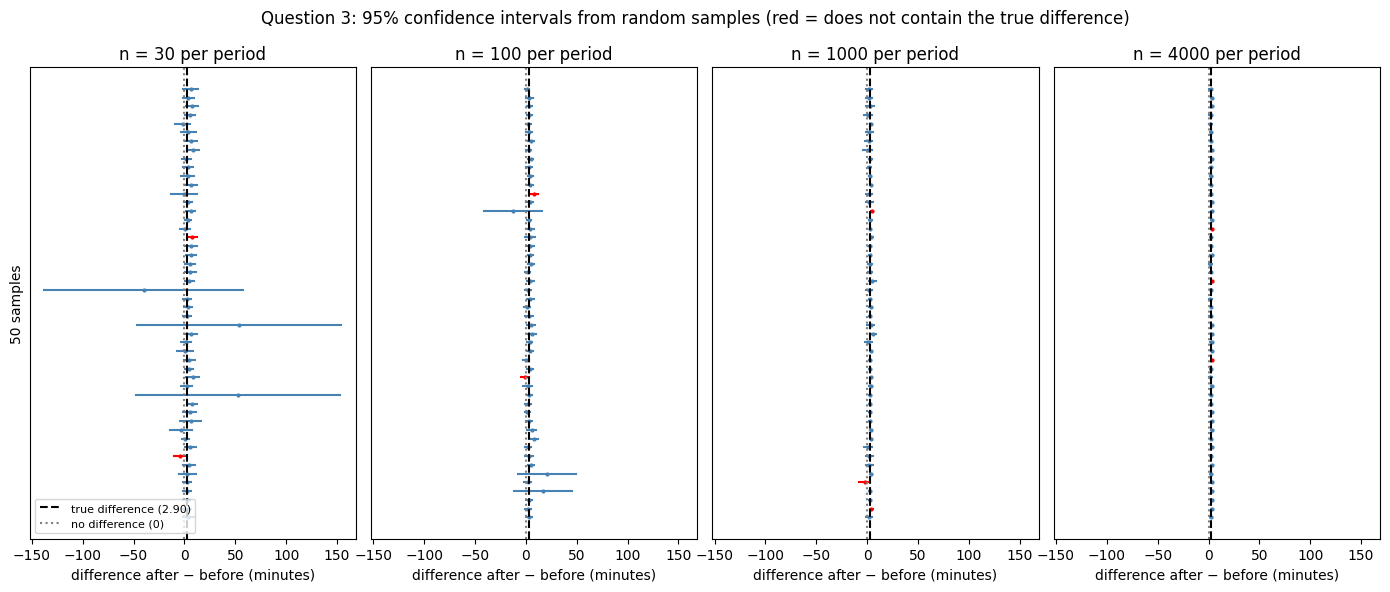

In [77]:
# 95% confidence intervals of the first 50 samples of each size.
# Red = the interval does not contain the true difference.
N_SHOWN = 50

fig, axes = plt.subplots(1, len(SAMPLE_SIZES), figsize=(14, 6), sharex=True, sharey=True)

for ax, n in zip(axes, SAMPLE_SIZES):
    shown = results_q3[results_q3["n"] == n].head(N_SHOWN).reset_index(drop=True)
    for i, row in shown.iterrows():
        color = "steelblue" if row["covers"] else "red"
        ax.plot([row["lower"], row["upper"]], [i, i], color=color, lw=1.5)
        ax.plot(row["diff"], i, "o", color=color, ms=2)
    ax.axvline(true_diff_q3, color="black", ls="--", label="true difference (2.90)")
    ax.axvline(0, color="gray", ls=":", label="no difference (0)")
    ax.set_title(f"n = {n} per period")
    ax.set_xlabel("difference after − before (minutes)")
    ax.set_yticks([])

axes[0].set_ylabel(f"{N_SHOWN} samples")
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle("Question 3: 95% confidence intervals from random samples "
             "(red = does not contain the true difference)")
plt.tight_layout()
plt.show()

#### Results with random samples

| Sample size per period | Mean CI width (min) | CIs containing 2.90 (%) | Tests rejecting H₀ (%) |
|---|---|---|---|
| 30 | 15.2 | 95.6 | 20.6 |
| 100 | 8.7 | 95.6 | 51.6 |
| 1000 | 3.5 | 93.7 | 75.3 |
| 4000 | 2.0 | 92.6 | 99.1 |

- **Width:** the interval narrows as the sample grows, from 15.2 minutes with
  30 fires to 2.0 minutes with 4000.
- **Coverage:** close to 95% with 30, 100 and 1000 fires, but lower with 4000
  (92.6%; 92.9% when the simulation is repeated with another seed). We look
  at the reason below.
- **Test:** the test detects the difference in 21% of the samples of 30 fires,
  52% with 100, 75% with 1000 and 99% with 4000.

Compared with question 1, the difference is detected far more often with the
same sample sizes (99% against 70% with 4000 fires): relative to the
variability of the data, the increase in intervention time is easier to
detect than the change in the share of negligent fires.

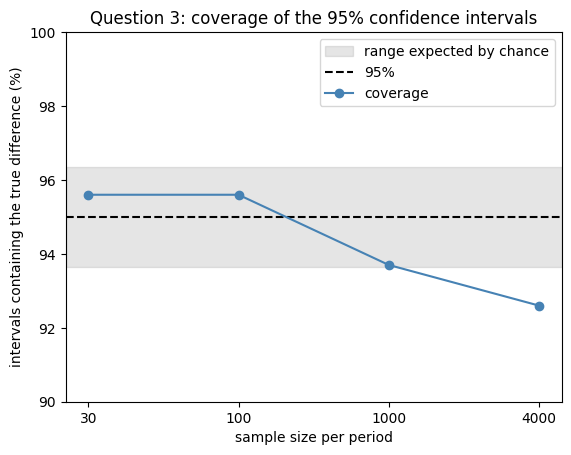

In [78]:
# Coverage per sample size, with the range expected by chance alone
# for a true 95% coverage and 1000 samples (±1.96 × √(0.95 × 0.05 / 1000)).
margin = 1.96 * np.sqrt(0.95 * 0.05 / REPETITIONS) * 100

coverage = summary_samples_q3["coverage_pct"]

fig, ax = plt.subplots()
ax.axhspan(95 - margin, 95 + margin, color="gray", alpha=0.2, label="range expected by chance")
ax.axhline(95, color="black", ls="--", label="95%")
ax.plot(coverage.index.astype(str), coverage.values, "o-", color="steelblue", label="coverage")
ax.set_xlabel("sample size per period")
ax.set_ylabel("intervals containing the true difference (%)")
ax.set_ylim(90, 100)
ax.set_title("Question 3: coverage of the 95% confidence intervals")
ax.legend()
plt.show()

In [79]:
# Intervals that do not contain the true difference: above or below it?
misses = results_q3[~results_q3["covers"]].copy()
misses["side"] = np.where(misses["lower"] > true_diff_q3,
                          "interval above 2.90", "interval below 2.90")

pd.crosstab(misses["n"], misses["side"], margins=True)

side,interval above 2.90,interval below 2.90,All
n,,,
30,21,23,44
100,26,18,44
1000,60,3,63
4000,66,8,74
All,173,52,225


#### Why the coverage drops with large samples

With 30 and 100 fires, the intervals that miss the true difference are split
evenly above and below it, as expected by chance. With 1000 and 4000 fires,
almost all of them lie above it (60 of 63 and 66 of 74), so in those samples
the difference after − before is overestimated.

This is consistent with the extreme intervention times, which weigh more
before 2018 (standard deviation 27.65 against 18.18 minutes): a sample that
misses them underestimates the mean before 2018. With small samples the
interval is wide enough to absorb this; with large samples it is narrow and
misses the true value more often.

The interval for the mean still works reasonably well, but the extreme values
make it slightly less reliable than the nominal 95%.

**What the samples add:** the increase in intervention time is clearer than the
change in question 1 and is detected even with a few hundred fires. The extreme
values make the 95% interval slightly less reliable with large samples.

### Exam reference: reusable independent-samples t-test


Adapt the dataset, column names, group labels, alternative hypothesis,
variance assumption and significance level (`alpha`).

#### Hypotheses

Let μ₁ and μ₂ represent the population means in groups 1 and 2.

- H₀: μ₁ = μ₂
- H₁: μ₁ ≠ μ₂ — use `alternative="two-sided"`.

For a one-sided test:

- H₁: μ₁ > μ₂ — use `alternative="greater"`.
- H₁: μ₁ < μ₂ — use `alternative="less"`.

#### Conditions checklist

**Numerical outcome and two groups**

The response variable is numerical, and the two groups are independent.
For paired observations, use a paired t-test instead.

**Independence**

Observations are independent within and between groups.

**Data collection**

Explain random sampling or random assignment, if applicable.
Otherwise, acknowledge limitations to generalisation.

For sampling without replacement, check that each sample is less
than 10% of its population.

**Distributions and sample sizes**

For small samples, within-group distributions should be approximately
normal, without strong skewness or extreme outliers.

Larger samples allow greater departures from normality. Strong skewness
and influential extreme values still require attention; a large sample
does not automatically resolve every concern.

**Population variances**

- Welch's test (`equal_var=False`) does not assume equal population variances.
- The pooled t-test (`equal_var=True`) assumes equal population variances.

Equal group sizes are not required.

#### Interpretation

Compare the p-value with `alpha`, provided the conditions are adequately met.
Report the group means and their difference alongside the test result.

In [ ]:
import pandas as pd
from scipy.stats import ttest_ind

# REUSABLE TEMPLATE — INDEPENDENT-SAMPLES T-TEST

# CHANGE THESE FOR A NEW DATASET
df = q3
group_column = "period"
value_column = "time_first_intervention_min"

group1 = "before"
group2 = "after"

alpha = 0.05

# Choose ONE setting:
# "two-sided" → H1: μ1 ≠ μ2
# "greater"   → H1: μ1 > μ2
# "less"      → H1: μ1 < μ2
# μ1 refers to group1; μ2 refers to group2.
alternative = "two-sided"

# False = Welch; True = pooled t-test (assumes equal variances).
equal_var = False

# KEEP THE CODE BELOW THE SAME
# Select the two groups and exclude missing numerical values.
values1 = df.loc[df[group_column] == group1, value_column].dropna()
values2 = df.loc[df[group_column] == group2, value_column].dropna()

# Descriptive statistics presented as a table.
summary = pd.DataFrame({
    group1: values1.describe(),
    group2: values2.describe()
}).T

display(summary)

# Descriptive difference: group2 minus group1.
difference = values2.mean() - values1.mean()
print(f"Mean difference ({group2} − {group1}): {difference:.2f}")

# Test compares group1 minus group2.
t_stat, p_value = ttest_ind(
    values1,
    values2,
    equal_var=equal_var,
    alternative=alternative
)

print(f"\nt-statistic: {t_stat:.3f}")
print(f"p-value: {p_value:.3e}")
print("Significance level:", alpha)

# Interpret only after assessing the conditions separately.
if p_value < alpha:
    print("Reject H0: evidence supporting the chosen alternative hypothesis.")
else:
    print("Do not reject H0: insufficient evidence supporting the alternative.")

,count,mean,std,min,25%,50%,75%,max
before,204631.0,13.199022,27.654778,1.0,7.0,10.0,15.0,1472.0
after,71638.0,16.102557,18.180429,1.0,9.0,13.0,19.0,1488.0


Mean difference (after − before): 2.90

t-statistic: -31.772
p-value: 5.890e-221
Significance level: 0.05
Reject H0: evidence supporting the chosen alternative hypothesis.


### Exam reference: confidence interval for one mean


Use it to estimate a single population mean μ, for example the mean
time to first intervention in one period.

#### Formula

CI = x̄ ± t* × SE, with SE = s / √n

- x̄: sample mean, s: sample standard deviation, n: number of observations
- t*: critical value of the t distribution with n − 1 degrees of freedom
  (`t.ppf(1 - (1 - confidence) / 2, n - 1)`)

#### Conditions checklist

**Independence**

Observations are independent. With random sampling without replacement,
the sample is less than 10% of the population.

**Distribution and sample size**

For small samples, the data should be approximately normal, without
strong skewness or extreme outliers. Larger samples allow more skewness,
but extreme values still require attention.

#### Interpretation

"We are 95% confident that the population mean of [variable]
is between [lower] and [upper]."

In [67]:
from scipy.stats import t
import numpy as np

# REUSABLE TEMPLATE — CONFIDENCE INTERVAL FOR ONE MEAN

# CHANGE THESE FOR A NEW DATASET
df = q3[q3["period"] == "after"]     # the group to estimate
value_column = "time_first_intervention_min"

confidence = 0.95

# KEEP THE CODE BELOW THE SAME
values = df[value_column].dropna()
n = len(values)
mean = values.mean()
s = values.std()                     # sample standard deviation (n − 1)

se = s / np.sqrt(n)
t_crit = t.ppf(1 - (1 - confidence) / 2, n - 1)

lower = mean - t_crit * se
upper = mean + t_crit * se

print(f"mean: {mean:.4f}, s: {s:.4f}, n: {n}")
print(f"SE: {se:.4f}, df: {n - 1}, t*: {t_crit:.3f}")
print(f"{confidence:.0%} CI: [{lower:.4f}, {upper:.4f}]")

mean: 16.1026, s: 18.1804, n: 71638
SE: 0.0679, df: 71637, t*: 1.960
95% CI: [15.9694, 16.2357]


### Exam reference: random samples, confidence intervals, tests and power (two means)

Draws pairs of random samples of different sizes from two groups and, for
each pair, computes the 95% confidence interval for the difference in means
and the two-sided test. Then computes the power of the test for a given
true difference.

#### amostras, IC e teste

In [83]:
from scipy.stats import t, ttest_ind
import numpy as np

# REUSABLE TEMPLATE — PAIRS OF RANDOM SAMPLES: CI + TEST FOR TWO MEANS
# One pair = one random sample from group 1 + one random sample from group 2.
# Question type: "generate at least ten pairs of random samples with three
# different sample sizes" and repeat the CI and the test for each pair.

# CHANGE THESE FOR A NEW DATASET
df = q3                                         # the complete dataset
group_column = "period"                         # column with the two groups
value_column = "time_first_intervention_min"    # numerical column
group1 = "before"
group2 = "after"

sample_sizes = [10, 30, 60]   # sizes asked in the question (same n in both groups)
n_pairs = 10                  # pairs of samples per size (at least 10)
confidence = 0.95
alpha = 0.05
# "two-sided" -> H1: mu1 ≠ mu2 | "greater" -> H1: mu1 > mu2 | "less" -> H1: mu1 < mu2
alternative = "two-sided"
seed = 42                     # fixed seed = same samples every time you run it

# KEEP THE CODE BELOW THE SAME
pop1 = df.loc[df[group_column] == group1, value_column].dropna().to_numpy()
pop2 = df.loc[df[group_column] == group2, value_column].dropna().to_numpy()

# 10% condition: each sample must be less than 10% of its population.
print("population sizes:", len(pop1), len(pop2))
print("10% condition holds for all sizes:",
      max(sample_sizes) < 0.1 * min(len(pop1), len(pop2)))

rng = np.random.default_rng(seed)
rows = []
for n in sample_sizes:
    for pair in range(1, n_pairs + 1):
        # One random sample from each group, without replacement.
        s1 = rng.choice(pop1, size=n, replace=False)
        s2 = rng.choice(pop2, size=n, replace=False)

        # Welch CI for mu1 - mu2.
        v1, v2 = s1.var(ddof=1) / n, s2.var(ddof=1) / n
        diff = s1.mean() - s2.mean()
        se = np.sqrt(v1 + v2)
        df_w = (v1 + v2) ** 2 / (v1 ** 2 / (n - 1) + v2 ** 2 / (n - 1))
        t_crit = t.ppf(1 - (1 - confidence) / 2, df_w)

        # Welch t-test, H0: mu1 = mu2.
        t_stat, p_value = ttest_ind(s1, s2, equal_var=False, alternative=alternative)

        rows.append({"n": n, "pair": pair,
                     "mean1": s1.mean(), "sd1": s1.std(ddof=1),
                     "mean2": s2.mean(), "sd2": s2.std(ddof=1),
                     "diff (1 - 2)": diff,
                     "CI lower": diff - t_crit * se, "CI upper": diff + t_crit * se,
                     "CI width": 2 * t_crit * se,
                     "t": t_stat, "p-value": p_value, "reject H0": p_value < alpha})

# All the results (means and sd are kept here for the power).
samples = pd.DataFrame(rows).round(3)

# Main table for the answer: one CI and one test per pair.
display(samples[["n", "pair", "diff (1 - 2)", "CI lower", "CI upper", "p-value", "reject H0"]])

# Summary per size: mean CI width and how many of the n_pairs tests reject H0.
display(samples.groupby("n").agg(mean_CI_width=("CI width", "mean"),
                                 rejections=("reject H0", "sum")))

population sizes: 204631 71638
10% condition holds for all sizes: True


,n,pair,diff (1 - 2),CI lower,CI upper,p-value,reject H0
0,10,1,-5.300,-14.632,4.032,0.248,False
1,10,2,4.300,-5.227,13.827,0.342,False
2,10,3,1.000,-9.496,11.496,0.843,False
3,10,4,-6.100,-14.983,2.783,0.161,False
4,10,5,-1.700,-11.641,8.241,0.724,False
5,10,6,-3.200,-10.508,4.108,0.370,False
6,10,7,1.900,-5.201,9.001,0.580,False
7,10,8,-3.600,-11.184,3.984,0.332,False
8,10,9,-14.900,-34.347,4.547,0.119,False
9,10,10,-2.100,-10.934,6.734,0.622,False


,mean_CI_width,rejections
n,,
10,19.6911,0
30,10.4415,4
60,7.0580,3


#### potência com valores dados (pergunta 2a, amostras do enunciado)

In [85]:
from scipy.stats import norm
import numpy as np

# REUSABLE TEMPLATE — POWER OF THE TEST FOR TWO MEANS
#
# What power is:
#   alpha = P(reject H0 | H0 is true)    -> false alarm
#   power = P(reject H0 | H0 is false)   -> detecting a real difference
#   power = 1 - beta, beta = P(not rejecting H0 | H0 is false)
#
# Power depends on:
#   - the true difference (delta): bigger difference -> more power
#   - the variability (sd):        more variability  -> less power
#   - the sample size (n):         bigger n          -> more power (smaller SE)
#   - alpha:                       smaller alpha     -> less power
#
# How it is computed (normal approximation):
#   1. SE = sqrt(sd1^2/n1 + sd2^2/n2)
#   2. H0 is rejected when diff / SE passes z*
#   3. If the true difference is delta, diff / SE is centred at delta / SE
#   4. power = probability that it still passes z*
#
# Uses only: delta, sd1, sd2, n1, n2, alpha. It does NOT use the CI or the p-value.

# CHANGE THESE FOR A NEW QUESTION
delta = -3          # true difference mu1 - mu2 given in the question
sd1, n1 = 27.65, 60 # group 1: sd and n (from the question's samples)
sd2, n2 = 18.18, 60 # group 2: sd and n
alpha = 0.05
# same as in the test; for a one-sided test, delta must go in the direction of H1
alternative = "two-sided"

# KEEP THE CODE BELOW THE SAME
se = np.sqrt(sd1 ** 2 / n1 + sd2 ** 2 / n2)

if alternative == "two-sided":
    z_crit = norm.ppf(1 - alpha / 2)
    power = norm.cdf(delta / se - z_crit) + norm.cdf(-delta / se - z_crit)
else:
    z_crit = norm.ppf(1 - alpha)          # one-sided: all of alpha in one tail
    power = norm.cdf(abs(delta) / se - z_crit)

print(f"SE: {se:.4f}, z*: {z_crit:.3f}, delta/SE: {delta / se:.3f}")
print(f"power: {power:.3f} -> a real difference of {delta} is detected "
      f"in {power:.0%} of the samples of this size")

SE: 4.2721, z*: 1.960, delta/SE: -0.702
power: 0.108 -> a real difference of -3 is detected in 11% of the samples of this size


#### potência de um par de cada tamanho 

In [86]:
from scipy.stats import norm
import numpy as np

# POWER FOR ONE PAIR OF EACH SAMPLE SIZE (question 2a, generated samples)
# Uses the sd1, sd2 and n of one pair of each size from the table `samples`
# (cell 1), and the same formula as cell 2.

# CHANGE THESE FOR A NEW QUESTION
delta = -3                   # true difference mu1 - mu2 given in the question
alpha = 0.05
alternative = "two-sided"    # same as in the test
pair_used = 1                # which pair of each size to use

# KEEP THE CODE BELOW THE SAME
one_pair = samples[samples["pair"] == pair_used][["n", "sd1", "sd2"]].copy()
one_pair["SE"] = np.sqrt(one_pair["sd1"] ** 2 / one_pair["n"]
                         + one_pair["sd2"] ** 2 / one_pair["n"])

if alternative == "two-sided":
    z_crit = norm.ppf(1 - alpha / 2)
    one_pair["power"] = (norm.cdf(delta / one_pair["SE"] - z_crit)
                         + norm.cdf(-delta / one_pair["SE"] - z_crit))
else:
    z_crit = norm.ppf(1 - alpha)
    one_pair["power"] = norm.cdf(abs(delta) / one_pair["SE"] - z_crit)

display(one_pair.round(3))

,n,sd1,sd2,SE,power
0,10,10.480,9.334,4.438,0.104
10,30,4.725,7.545,1.625,0.455
20,60,12.587,8.980,1.996,0.324


## Question 4: Mean wildfire duration by municipality

Does the population mean wildfire duration differ between Paredes,
Castelo de Paiva, Évora and Santarém?

Duration is measured in hours.

### Hypotheses

- H₀: The population mean duration is equal across all four municipalities.
- H₁: At least one population mean differs.

The significance level is α = 0.05.

### Conditions and assumptions

**Independence**

Each record represents a separate fire assigned to one municipality.
The groups are not paired. Independence within and between municipalities
is assumed; shared temporal and geographical factors may limit this assumption.

**Group sizes and skewness**

Wildfire durations are strongly right-skewed. However, all four groups
are large, supporting approximately normal sampling distributions
of the group means. Extreme durations can still influence the results.

**Population variances**

We use Welch's one-way ANOVA because the group standard deviations
and sample sizes differ. Equal population variances are not required.

**Data coverage**

The analysis uses administrative records rather than random samples.
Results apply to fires retained after the duration cleaning;
missing and excluded observations may limit generalisation.

In [ ]:
# q24 contains the fires of the four municipalities
# with a valid duration (missing and 0 durations removed).
summary_q4 = q24.groupby("Concelho", observed=True)[
    "Duracao_Horas"
].agg(["count", "mean", "std", "median", "min", "max"])

summary_q4

,count,mean,std,median,min,max
Concelho,,,,,,
paredes,12492,1.278609,2.831771,0.816667,0.016667,143.600000
castelo de paiva,1392,1.790577,4.209986,1.083333,0.050000,83.250000
santarém,2985,1.552446,4.063688,0.816667,0.016667,82.666667
évora,1631,1.280421,2.416428,0.700000,0.066667,29.050000



We use Welch's one-way ANOVA because it does not assume equal
population variances across municipalities.

In [ ]:
from statsmodels.stats.oneway import anova_oneway

# Compare population mean durations without assuming equal variances.
result_q4 = anova_oneway(
    data=q24["Duracao_Horas"],
    groups=q24["Concelho"],
    use_var="unequal"
)

print(f"F-statistic: {result_q4.statistic:.3f}")
print(f"Numerator degrees of freedom: {result_q4.df_num:.2f}")
print(f"Denominator degrees of freedom: {result_q4.df_denom:.2f}")
print(f"p-value: {result_q4.pvalue:.3e}")

F-statistic: 10.083


Numerator degrees of freedom: 3.00
Denominator degrees of freedom: 3540.91
p-value: 1.300e-06


### Results and conclusion

Mean wildfire duration was:

- Castelo de Paiva: 1.79 hours
- Paredes: 1.28 hours
- Santarém: 1.55 hours
- Évora: 1.28 hours

Welch's one-way ANOVA gave F(3, 3540.91) = 10.08,
p = 1.30 × 10⁻⁶. At the 5% significance level, we reject H₀.

There is statistically significant evidence that at least one
municipality has a different population mean wildfire duration.

Castelo de Paiva had the highest observed mean. However, this overall
test does not identify which specific pairs of municipalities differ
significantly.

The analysis assumes independent observations. Durations are strongly
right-skewed, and extreme values can influence the means. Results apply
to fires retained after the duration cleaning.

### Exam reference: one-way ANOVA, ordinary or Welch



- H₀: all population group means are equal.
- H₁: at least one population mean differs (no directional alternative).

**Which ANOVA to use**

- Ordinary ANOVA assumes equal population variances. Use it when the largest
  group standard deviation is at most about twice the smallest.
- Welch's ANOVA does not assume equal variances. Use it when the ratio is
  above 2, especially if the group sizes are also very different.

**Other conditions:** independent observations (groups not paired); within
each group, approximately normal data or groups large enough, with
attention to strong skewness and extreme values.

The code checks the standard deviations, recommends one of the two,
and runs both so they can be compared.

In [ ]:
from statsmodels.stats.oneway import anova_oneway
from statsmodels.formula.api import ols
import statsmodels.api as sm

# REUSABLE TEMPLATE — ONE-WAY ANOVA: ORDINARY OR WELCH

# CHANGE THESE FOR A NEW DATASET
df = q24
group_column = "Concelho"          # column with the groups (3 or more)
value_column = "Duracao_Horas"     # numerical column
alpha = 0.05
sd_ratio_limit = 2                 # largest sd / smallest sd above this -> Welch

# KEEP THE CODE BELOW THE SAME
data_a = (df[[group_column, value_column]].dropna()
          .rename(columns={group_column: "group", value_column: "value"}))

# 1. Descriptive statistics per group
summary = data_a.groupby("group", observed=True)["value"].agg(["count", "mean", "std"])
display(summary.round(3))

# 2. Equal variances? Compare the standard deviations.
sd_ratio = summary["std"].max() / summary["std"].min()
equal_ok = sd_ratio <= sd_ratio_limit
print(f"largest sd / smallest sd: {sd_ratio:.2f} (limit {sd_ratio_limit})")
print("->", "equal variances reasonable: use ORDINARY ANOVA" if equal_ok
      else "variances differ: use WELCH's ANOVA (ordinary only for comparison)")

# 3. Ordinary ANOVA (assumes equal variances), with the ANOVA table
model = ols("value ~ C(group)", data=data_a).fit()
table = sm.stats.anova_lm(model, typ=1)

print("\nOrdinary ANOVA table:")
display(table.round(4))
f_ord, p_ord = table["F"].iloc[0], table["PR(>F)"].iloc[0]
print(f"Ordinary: F({table['df'].iloc[0]:.0f}, {table['df'].iloc[1]:.0f}) = {f_ord:.3f}, "
      f"p = {p_ord:.3e}")

# 4. Welch's ANOVA (does not assume equal variances)
welch = anova_oneway(data_a["value"], data_a["group"], use_var="unequal")

print(f"Welch:    F({welch.df_num:.0f}, {welch.df_denom:.2f}) = {welch.statistic:.3f}, "
      f"p = {welch.pvalue:.3e}")

# 5. Decision with the recommended ANOVA
p_main = p_ord if equal_ok else welch.pvalue
print("\nRecommended:", "ordinary" if equal_ok else "Welch")
print("Reject H0: at least one mean differs." if p_main < alpha
      else "Do not reject H0: no evidence that the means differ.")

,count,mean,std
group,,,
castelo de paiva,1392,1.791,4.210
paredes,12492,1.279,2.832
santarém,2985,1.552,4.064
évora,1631,1.280,2.416


largest sd / smallest sd: 1.74 (limit 2)
-> equal variances reasonable: use ORDINARY ANOVA

Ordinary ANOVA table:


,df,sum_sq,mean_sq,F,PR(>F)
C(group),3.0,461.6643,153.8881,15.5017,0.0
Residual,18496.0,183612.7167,9.9272,NaN,NaN


Ordinary: F(3, 18496) = 15.502, p = 4.554e-10
Welch:    F(3, 3540.91) = 10.083, p = 1.300e-06

Recommended: ordinary
Reject H0: at least one mean differs.


## Question 5: Association between intervention time and burned area

Is time to first intervention associated with burned area in mainland
Portugal during 2008–2025?

The descriptive statistics and scatterplots presented above show
strong right skewness and extreme values, particularly for burned area.

We use Spearman's rank correlation to assess whether longer intervention
times tend to accompany larger or smaller burned areas. This rank-based
method is less sensitive to extreme magnitudes than Pearson's correlation
and does not require normally distributed variables.

### Hypotheses

- H₀: The population Spearman correlation is zero.
- H₁: The population Spearman correlation is not zero.

We use a two-sided test at α = 0.05 and assume independent observations.

### Conditions and assumptions

**Paired measurements**

Each fire contributes a pair of measurements: time to first intervention
and burned area. Both variables are quantitative.

**Independence**

Observations from different fires are assumed independent.
Shared temporal and geographical factors may limit this assumption.

**Type of relationship**

Spearman's correlation measures monotonic association: whether larger
values of one variable tend to accompany larger or smaller values
of the other. It does not require a linear relationship or normally
distributed variables.

A correlation near zero would not rule out every possible relationship.

**Data coverage**

The analysis includes fires from 2008–2025 retained after cleaning
with both measurements available. Missing and excluded observations
may limit generalisation.

In [ ]:
from scipy.stats import spearmanr

# Calculate rank correlation using the original values.
# No log transformation is required.
rho, p_value = spearmanr(
    q5["time_first_intervention_min"],
    q5["AreaTotal_ha"],
    alternative="two-sided"
)

print("Number of fires:", len(q5))
print(f"Spearman correlation: {rho:.3f}")

# Extremely small p-values may be represented numerically as zero.
if p_value < 0.001:
    print("p-value: < 0.001")
else:
    print(f"p-value: {p_value:.3f}")

Number of fires: 270096
Spearman correlation: 0.196
p-value: < 0.001


,fires,median,q25,q75
time_first_intervention_min,,,,
1-5,41894,0.03,0.010,0.200
6-10,81689,0.04,0.010,0.250
11-15,69039,0.06,0.010,0.500
16-20,36477,0.10,0.012,0.720
21-30,26542,0.14,0.020,1.000
31-45,9953,0.30,0.030,1.549
46-60,2446,0.50,0.050,2.420
over 60,2056,1.00,0.120,5.000


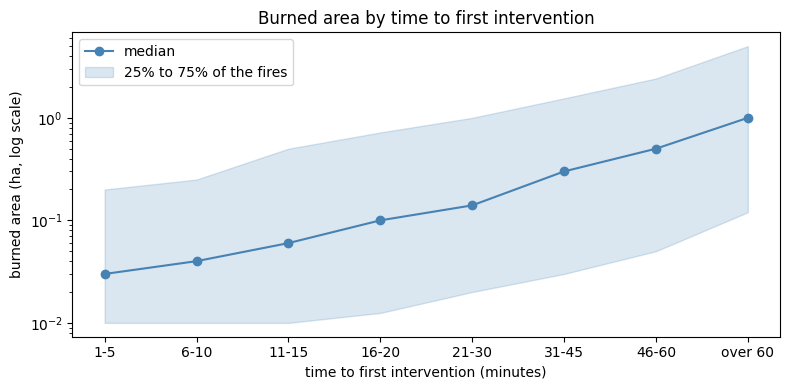

In [94]:
# Burned area by intervals of time to first intervention:
# median and the middle 50% of the fires in each interval.
bins = [0, 5, 10, 15, 20, 30, 45, 60, 1500]
labels = ["1-5", "6-10", "11-15", "16-20", "21-30", "31-45", "46-60", "over 60"]
groups = pd.cut(q5["time_first_intervention_min"], bins=bins, labels=labels)

by_time = q5.groupby(groups, observed=True)["AreaTotal_ha"].agg(
    fires="count", median="median",
    q25=lambda a: a.quantile(0.25), q75=lambda a: a.quantile(0.75))
display(by_time.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
x = range(len(by_time))
ax.plot(x, by_time["median"], "o-", color="steelblue", label="median")
ax.fill_between(x, by_time["q25"], by_time["q75"], color="steelblue", alpha=0.2,
                label="25% to 75% of the fires")
ax.set_xticks(list(x))
ax.set_xticklabels(by_time.index)
ax.set_yscale("log")
ax.set_xlabel("time to first intervention (minutes)")
ax.set_ylabel("burned area (ha, log scale)")
ax.set_title("Burned area by time to first intervention")
ax.legend()
plt.tight_layout()
plt.show()

### Results and conclusion

Among 270,096 fires, Spearman's correlation between time to first
intervention and burned area was ρₛ = 0.196 (t = 103.9, p < 0.001).
At the 5% significance level, we reject H₀. There is statistically
significant evidence of a weak positive monotonic association:
longer intervention times tend to accompany larger burned areas.

The table and figure show both sides of this result. The median burned
area rises in every interval of intervention time, from 0.03 ha when the
first intervention happens within 5 minutes to 1.00 ha when it takes more
than 60 minutes, so the trend is clear. But within each interval the
burned areas vary widely and the intervals overlap a lot, which is why
the correlation is weak. Most fires (85%) have their first intervention
within 20 minutes.

- The large number of observations allows even weak associations to be
statistically significant. The correlation's magnitude therefore matters
alongside its p-value.

- This association does not establish causation. Weather, terrain,
accessibility and other factors may influence both variables.

The analysis assumes independent observations and applies to fires
from 2008–2025 retained after cleaning with both variables available
and a burned area greater than 0.

### Exam reference: reusable Spearman correlation


Adapt the dataset, the two numerical columns, alternative hypothesis
and significance level (`alpha`).

#### Hypotheses

Let ρₛ represent the population Spearman rank correlation.

- H₀: ρₛ = 0
- H₁: ρₛ ≠ 0 — use `alternative="two-sided"`.

For a one-sided test:

- H₁: ρₛ > 0 — use `alternative="greater"`.
- H₁: ρₛ < 0 — use `alternative="less"`.

#### Conditions checklist

**Paired measurements**

Each observation contributes two measurements from the same unit.
Both variables must be numerical or ordinal and must vary.

Remove missing values as complete pairs to preserve the matching
between measurements.

**Independence**

Different observational units are assumed independent.
Repeated measurements of the same subjects require a different approach.

**Data collection**

Explain random sampling, if applicable.
Otherwise, acknowledge limitations to generalisation.

For sampling without replacement, check that the sample is less
than 10% of its population.

**Type of relationship**

Spearman measures monotonic association using ranks:
whether larger values of one variable tend to accompany larger
or smaller values of the other.

Inspect a scatterplot. A correlation near zero does not rule out
a non-monotonic relationship, such as a U-shaped pattern.

Normality and a linear relationship are not required.
Extreme magnitudes have less influence than in Pearson correlation,
but invalid observations still require attention.

**Sample size**

The function's approximate p-value is most reliable for large samples.
For small samples, consider a permutation test.

#### Interpretation

Compare the p-value with `alpha`, provided the conditions are adequately met.

Report the coefficient's direction and strength as well as significance.
Correlation does not establish causation.

In [ ]:
import pandas as pd
from scipy.stats import spearmanr

# REUSABLE TEMPLATE — SPEARMAN CORRELATION

# CHANGE THESE FOR A NEW DATASET
df = q5
x_column = "time_first_intervention_min"
y_column = "AreaTotal_ha"

alpha = 0.05

# Choose ONE setting:
# "two-sided" → H1: population Spearman correlation ≠ 0
# "greater"   → H1: population Spearman correlation > 0
# "less"      → H1: population Spearman correlation < 0
alternative = "two-sided"

# KEEP THE CODE BELOW THE SAME
# Retain complete pairs; do not drop missing values separately.
analysis_data = df[[x_column, y_column]].dropna()

# Descriptive statistics for both variables.
display(analysis_data.describe())

# Calculate correlation using ranks, without transforming the values.
rho, p_value = spearmanr(
    analysis_data[x_column],
    analysis_data[y_column],
    alternative=alternative
)

print("Number of observations:", len(analysis_data))
print(f"Spearman correlation: {rho:.3f}")

# Extremely small p-values may be represented numerically as zero.
if p_value == 0:
    print("p-value: below numerical precision (report as p < 0.001)")
else:
    print(f"p-value: {p_value:.3e}")

print("Significance level:", alpha)

# Interpret only after assessing the conditions separately.
if pd.isna(p_value):
    print("Test undefined: check sample size and whether both variables vary.")
elif p_value < alpha:
    print("Reject H0: evidence supporting the chosen alternative hypothesis.")
else:
    print("Do not reject H0: insufficient evidence supporting the alternative.")

,time_first_intervention_min,AreaTotal_ha
count,270096.000000,270096.000000
mean,13.987201,7.743308
std,25.168162,289.917945
min,1.000000,0.000001
25%,7.000000,0.010000
50%,11.000000,0.050000
75%,17.000000,0.500000
max,1488.000000,65478.286936


Number of observations: 270096
Spearman correlation: 0.196
p-value: below numerical precision (report as p < 0.001)
Significance level: 0.05
Reject H0: evidence supporting the chosen alternative hypothesis.


## Conclusion

**Research question:** Do rural wildfire characteristics differ across
municipalities and between the periods before and after 2017?

Yes: every characteristic we analysed differs, both between periods and
between municipalities, but most differences are small.

**Before and after 2017 (mainland Portugal)**

- Human negligence weighs slightly more after 2017: among fires with a
  known negligent or intentional cause, the share of negligent fires rose
  from 62.73% to 65.38% (95% CI for the difference: 2.09 to 3.22
  percentage points).
- The first intervention takes longer after 2017: the mean time rose from
  13.20 to 16.10 minutes (95% CI for the difference: 2.72 to 3.08 minutes),
  and the median from 10 to 13 minutes, so the change affects the typical
  fire and not only extreme cases.

The random samples show that these two changes are not equally strong.
The increase in intervention time is detected even with a few hundred
fires per period, while the change in the share of negligent fires is
only detected reliably with thousands. The very small p-values obtained
with all the data come mainly from the size of the data.

**Across Paredes, Castelo de Paiva, Évora and Santarém**

- Fires lasting 24 hours or more are rare everywhere (below 1%), but their
  share differs: in Santarém it is about three times that of Paredes
  (0.87% against 0.29%).
- Mean duration differs, from 1.28 hours (Paredes, Évora) to 1.79 hours
  (Castelo de Paiva).

The municipality with the longest fires on average (Castelo de Paiva) is
not the one with the most exceptionally long fires (Santarém), so typical
and extreme fires give different pictures of the municipalities.

**Intervention time and burned area**

Fires with a later first intervention tend to burn larger areas: the
median burned area rises from 0.03 ha (first intervention within 5
minutes) to 1.00 ha (more than 60 minutes). The association is weak
(ρₛ = 0.196) because burned areas vary widely among fires with similar
intervention times.

**Limitations**

The data are administrative records, not random samples, and the study is
observational, so the results describe associations, not causes. The cause
is missing for most fires before 2014 and the first intervention date
before 2008, which limits questions 1, 3 and 5. Fires of 24 hours or more
are few in each municipality (8 to 36), so the percentages in question 2
are sensitive to small changes in these counts.